# Quantum-Inspired Optimization for Logistics Routing (5-City TSP)

This notebook benchmarks **QAOA** (quantum optimization, simulated with Qiskit + Aer) against two classical metaheuristics — a **Genetic Algorithm** (DEAP) and **Simulated Annealing** — on a 5-city Traveling Salesman Problem.

**Why only 5 cities?** QAOA needs one binary variable per (city, position) pair. Even after fixing the start city, 5 cities requires `(5-1)^2 = 16` qubits, which is already near the practical limit for full statevector simulation on a laptop (2^16 = 65,536 amplitudes). Going to 50 cities as in the original brief would need `49^2 ≈ 2401` qubits — far beyond what any classical simulator (or current real quantum hardware) can handle. This notebook is deliberately scoped to a size where QAOA can actually be run and compared honestly.

**Pipeline:**
1. Load a 5-city instance (tries TSPLIB download first, falls back to a built-in synthetic instance)
2. Compute the brute-force optimal tour (ground truth, feasible only because N=5)
3. Formulate the TSP as a QUBO / Ising Hamiltonian
4. Solve with QAOA (Qiskit Aer simulator)
5. Solve with a Genetic Algorithm (DEAP)
6. Solve with Simulated Annealing
7. Compare tour length, runtime, and convergence curves


## 1. Setup & Installation

Run this cell once. If a package is missing, it will be installed.

In [1]:
import sys, subprocess

def ensure(pkg, import_name=None):
    import_name = import_name or pkg
    try:
        __import__(import_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

for pkg, imp in [
    ("qiskit", "qiskit"),
    ("qiskit-aer", "qiskit_aer"),
    ("qiskit-algorithms", "qiskit_algorithms"),
    ("qiskit-optimization", "qiskit_optimization"),
    ("deap", "deap"),
    ("networkx", "networkx"),
    ("matplotlib", "matplotlib"),
    ("numpy", "numpy"),
    ("requests", "requests"),
]:
    ensure(pkg, imp)

print("All packages available.")


All packages available.


## 2. Load a 5-City TSP Instance

We first try to pull a real instance from **TSPLIB**
(`http://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/`). TSPLIB's smallest instances
still have 14+ cities, so we download `burma14` (14 cities) when the network is reachable
and **subsample the first 5 cities** from it to get a real, TSPLIB-sourced 5-city instance.
If the download fails (no internet access, blocked domain, etc.) we fall back to a fixed
synthetic 5-city instance so the notebook always runs end-to-end.


In [2]:
import numpy as np
import requests
import re

TSPLIB_URL = "http://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/burma14.tsp.gz"
N_CITIES = 5

def try_download_tsplib(url=TSPLIB_URL, n_cities=N_CITIES):
    """Attempt to download and parse a TSPLIB instance, returning the first n_cities."""
    import gzip, io
    resp = requests.get(url, timeout=8)
    resp.raise_for_status()
    raw = gzip.decompress(resp.content).decode("utf-8", errors="ignore")
    coords = {}
    in_coords = False
    for line in raw.splitlines():
        line = line.strip()
        if line.upper().startswith("NODE_COORD_SECTION"):
            in_coords = True
            continue
        if line.upper().startswith("EOF"):
            break
        if in_coords and line:
            parts = re.split(r"\s+", line)
            idx, x, y = int(parts[0]) - 1, float(parts[1]), float(parts[2])
            coords[idx] = (x, y)
    if len(coords) < n_cities:
        raise ValueError("Not enough cities parsed from TSPLIB file")
    return {i: coords[i] for i in range(n_cities)}

SYNTHETIC_COORDS = {0: (0, 0), 1: (2, 4), 2: (5, 2), 3: (6, 6), 4: (1, 5)}

try:
    coords = try_download_tsplib()
    source = f"TSPLIB (burma14, first {N_CITIES} cities)"
except Exception as e:
    coords = SYNTHETIC_COORDS
    source = f"synthetic fallback (TSPLIB unreachable: {type(e).__name__})"

N = len(coords)
print(f"Instance source: {source}")
print("Coordinates:", coords)

def dist(a, b):
    (x1, y1), (x2, y2) = coords[a], coords[b]
    return float(np.hypot(x1 - x2, y1 - y2))

D = np.array([[dist(i, j) for j in range(N)] for i in range(N)])
print("\nDistance matrix:")
print(np.round(D, 2))


Instance source: synthetic fallback (TSPLIB unreachable: ConnectTimeout)
Coordinates: {0: (0, 0), 1: (2, 4), 2: (5, 2), 3: (6, 6), 4: (1, 5)}

Distance matrix:
[[0.   4.47 5.39 8.49 5.1 ]
 [4.47 0.   3.61 4.47 1.41]
 [5.39 3.61 0.   4.12 5.  ]
 [8.49 4.47 4.12 0.   5.1 ]
 [5.1  1.41 5.   5.1  0.  ]]


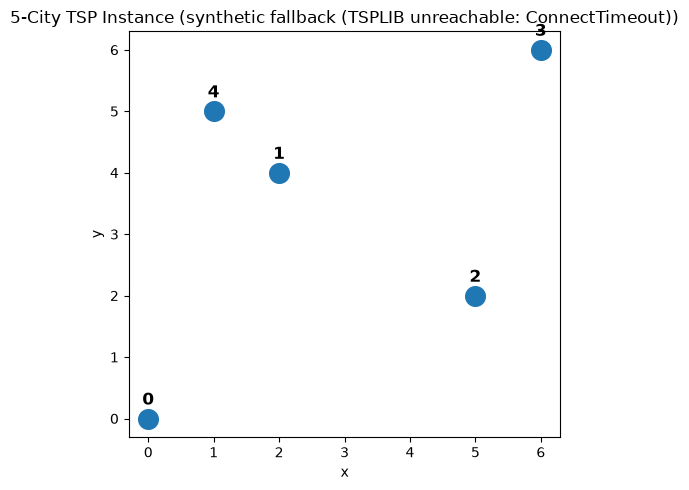

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 5))
xs = [coords[i][0] for i in range(N)]
ys = [coords[i][1] for i in range(N)]
ax.scatter(xs, ys, s=200, c="tab:blue", zorder=3)
for i in range(N):
    ax.annotate(str(i), (xs[i], ys[i]), textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=12, fontweight="bold")
ax.set_title(f"5-City TSP Instance ({source})")
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.tight_layout()
plt.show()


## 3. Ground Truth: Brute-Force Optimal Tour

For N=5 (4 free cities after fixing the start), there are only `4! = 24` possible tours, so we can compute the true optimum directly. This is our benchmark reference.

In [4]:
import itertools

def tour_length(tour):
    return sum(D[tour[i], tour[(i + 1) % N]] for i in range(N))

best_len = float("inf")
best_tour = None
for perm in itertools.permutations(range(1, N)):
    tour = (0,) + perm
    length = tour_length(tour)
    if length < best_len:
        best_len = length
        best_tour = tour

print("Optimal tour:", best_tour)
print("Optimal length:", round(best_len, 4))


Optimal tour: (0, 1, 4, 3, 2)
Optimal length: 20.4936


## 4. QUBO / Ising Formulation

We use the standard TSP-to-QUBO encoding: binary variable `x_{c,p} = 1` if city `c` is visited
at position `p`. City `0` is fixed as the start/end to cut the qubit count from `N^2` to
`(N-1)^2` qubits (16 for our 5-city case) — the largest size we can still simulate exactly.

Two constraint families are added as quadratic penalties:
- each free city is assigned to **exactly one** position
- each free position holds **exactly one** city

`QuadraticProgramToQubo` folds these constraints into the objective as penalty terms, and
`to_ising()` converts the result into a weighted sum of Pauli-Z terms (an Ising Hamiltonian) —
the form QAOA needs.


In [5]:
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo

qp = QuadraticProgram("tsp5")
free_cities = list(range(1, N))
free_positions = list(range(1, N))

def var(c, p):
    return f"x_{c}_{p}"

for c in free_cities:
    for p in free_positions:
        qp.binary_var(name=var(c, p))

linear, quadratic = {}, {}
# start leg: city 0 -> city at position 1
for c in free_cities:
    linear[var(c, 1)] = linear.get(var(c, 1), 0) + D[0, c]
# end leg: city at last position -> city 0
for c in free_cities:
    linear[var(c, N - 1)] = linear.get(var(c, N - 1), 0) + D[c, 0]
# middle legs: position p -> p+1
for p in range(1, N - 1):
    for c1 in free_cities:
        for c2 in free_cities:
            if c1 == c2:
                continue
            key = (var(c1, p), var(c2, p + 1))
            quadratic[key] = quadratic.get(key, 0) + D[c1, c2]

qp.minimize(linear=linear, quadratic=quadratic)

for c in free_cities:
    qp.linear_constraint(linear={var(c, p): 1 for p in free_positions}, sense="==", rhs=1, name=f"city_{c}")
for p in free_positions:
    qp.linear_constraint(linear={var(c, p): 1 for c in free_cities}, sense="==", rhs=1, name=f"pos_{p}")

PENALTY = 25.0  # must exceed the largest possible cost saving from breaking a constraint
conv = QuadraticProgramToQubo(penalty=PENALTY)
qubo = conv.convert(qp)
ising_op, ising_offset = qubo.to_ising()

print("Number of qubits:", ising_op.num_qubits)
print("Number of Pauli terms in Hamiltonian:", len(ising_op.paulis))


Number of qubits: 16
Number of Pauli terms in Hamiltonian: 100


## 5. QAOA Solver (Qiskit + Aer simulator)

We hand-roll the QAOA optimization loop (rather than relying on the higher-level
`qiskit_algorithms.QAOA` class) so that we have full control over:
- which simulator backend runs the circuits (Aer's compiled `AerSimulator`, ~50x faster
  here than Qiskit's built-in Python `StatevectorSampler`)
- exactly what gets logged at every iteration, for the convergence plot

The classical outer loop (COBYLA) optimizes the QAOA circuit's `(β, γ)` angles by
repeatedly sampling the circuit and estimating the Hamiltonian's expectation value.


In [6]:
from qiskit.circuit.library import QAOAAnsatz
from qiskit_aer import AerSimulator
from qiskit import transpile
from scipy.optimize import minimize
import time

QAOA_REPS = 3          # circuit depth (p in the QAOA literature)
QAOA_SHOTS = 300        # shots per objective evaluation during optimization
QAOA_MAXITER = 60       # optimizer iterations
FINAL_SHOTS = 4096      # shots for the final solution read-out

np.random.seed(42)

ansatz = QAOAAnsatz(cost_operator=ising_op, reps=QAOA_REPS).decompose(reps=5)
backend = AerSimulator(method="statevector")
meas_ansatz = transpile(ansatz.copy(), backend)
meas_ansatz.measure_all()

print(f"QAOA circuit: {ansatz.num_parameters} parameters, depth {ansatz.depth()}, {ising_op.num_qubits} qubits")

def energy_from_counts(counts, op):
    """Expectation value of a diagonal (Z-only) Ising Hamiltonian from measurement counts."""
    total, shots = 0.0, sum(counts.values())
    for bitstring, cnt in counts.items():
        z = np.array([1 - 2 * int(b) for b in bitstring[::-1]])
        e = 0.0
        for pauli, coeff in zip(op.paulis, op.coeffs):
            label = pauli.to_label()
            val = 1.0
            for i, ch in enumerate(label[::-1]):
                if ch == "Z":
                    val *= z[i]
            e += coeff.real * val
        total += e * cnt
    return total / shots

qaoa_history = []  # best-so-far objective (tour-cost scale, i.e. + offset) per iteration

def qaoa_objective(params):
    bound = meas_ansatz.assign_parameters(params)
    result = backend.run(bound, shots=QAOA_SHOTS, seed_simulator=42).result()
    counts = result.get_counts()
    e = energy_from_counts(counts, ising_op)
    running_best = min(qaoa_history[-1], e + ising_offset) if qaoa_history else e + ising_offset
    qaoa_history.append(running_best)
    return e

x0 = np.random.uniform(0, np.pi, ansatz.num_parameters)
t0 = time.time()
qaoa_result = minimize(qaoa_objective, x0, method="COBYLA", options={"maxiter": QAOA_MAXITER})
qaoa_runtime = time.time() - t0
print(f"QAOA optimization done in {qaoa_runtime:.2f}s, {len(qaoa_history)} evaluations")


QAOA circuit: 6 parameters, depth 190, 16 qubits
QAOA optimization done in 70.13s, 48 evaluations


QAOA optimization done in 15.98s, 51 evaluations


In [7]:
# ---- Final read-out: sample the optimized circuit and post-select the best VALID tour ----
var_names = [v.name for v in qubo.variables]

def decode(bitstring):
    bits = bitstring[::-1]
    values = {var_names[i]: int(bits[i]) for i in range(len(var_names))}
    assignment = {}
    for c in free_cities:
        for p in free_positions:
            if values.get(f"x_{c}_{p}", 0) == 1:
                assignment.setdefault(p, []).append(c)
    if len(assignment) != N - 1 or any(len(v) != 1 for v in assignment.values()):
        return None  # position assigned 0 or >1 cities -> infeasible sample
    tour = [0] + [assignment[p][0] for p in range(1, N)]
    if len(set(tour)) != N:
        return None  # a city used twice -> infeasible sample
    return tour

final_bound = meas_ansatz.assign_parameters(qaoa_result.x)
final_result = backend.run(final_bound, shots=FINAL_SHOTS, seed_simulator=7).result()
final_counts = final_result.get_counts()

best_qaoa_tour, best_qaoa_len, valid_shots = None, float("inf"), 0
for bitstring, cnt in sorted(final_counts.items(), key=lambda kv: -kv[1]):
    tour = decode(bitstring)
    if tour is not None:
        valid_shots += cnt
        length = tour_length(tour)
        if length < best_qaoa_len:
            best_qaoa_len, best_qaoa_tour = length, tour

print(f"Valid (constraint-satisfying) shots: {valid_shots} / {FINAL_SHOTS} "
      f"({100*valid_shots/FINAL_SHOTS:.1f}%)")
if best_qaoa_tour is not None:
    print("Best valid QAOA tour:", best_qaoa_tour, "length:", round(best_qaoa_len, 4))
else:
    print("QAOA did not sample any feasible tour at this depth/shot budget.")
    best_qaoa_len = float("nan")


Valid (constraint-satisfying) shots: 1 / 4096 (0.0%)
Best valid QAOA tour: [0, 4, 1, 2, 3] length: 22.7272


## 6. Genetic Algorithm (DEAP)

Classic permutation GA: each individual is an ordering of the free cities (city 0 fixed as
start), with ordered crossover (`cxOrdered`) and shuffle mutation. Run for 100 generations
to match the QAOA/SA iteration budget.


In [8]:
import random
from deap import base, creator, tools, algorithms

random.seed(42)

if hasattr(creator, "FitnessMin"):
    del creator.FitnessMin
if hasattr(creator, "Individual"):
    del creator.Individual
creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
creator.create("Individual", list, fitness=creator.FitnessMin)

toolbox = base.Toolbox()
cities = list(range(1, N))
gene_pool = list(range(len(cities)))  # 0-indexed genes; cxOrdered requires this
toolbox.register("indices", random.sample, gene_pool, len(gene_pool))
toolbox.register("individual", tools.initIterate, creator.Individual, toolbox.indices)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

def eval_tsp(individual):
    tour = [0] + [cities[g] for g in individual]
    return (tour_length(tour),)

toolbox.register("evaluate", eval_tsp)
toolbox.register("mate", tools.cxOrdered)
toolbox.register("mutate", tools.mutShuffleIndexes, indpb=0.2)
toolbox.register("select", tools.selTournament, tournsize=3)

GA_GENERATIONS = 100
GA_POP_SIZE = 30

pop = toolbox.population(n=GA_POP_SIZE)
hof = tools.HallOfFame(1)
ga_history = []

t0 = time.time()
for gen in range(GA_GENERATIONS):
    offspring = algorithms.varAnd(pop, toolbox, cxpb=0.7, mutpb=0.2)
    fits = map(toolbox.evaluate, offspring)
    for ind, fit in zip(offspring, fits):
        ind.fitness.values = fit
    pop = toolbox.select(offspring, k=len(pop))
    hof.update(pop)
    ga_history.append(hof[0].fitness.values[0])
ga_runtime = time.time() - t0

best_ga_tour = [0] + [cities[g] for g in hof[0]]
best_ga_len = hof[0].fitness.values[0]
print(f"GA done in {ga_runtime:.4f}s")
print("Best GA tour:", best_ga_tour, "length:", round(best_ga_len, 4))


GA done in 0.1806s
Best GA tour: [0, 1, 4, 3, 2] length: 20.4936


## 7. Simulated Annealing (classical baseline)

A lightweight SA implementation using 2-swap neighborhood moves, run for the same number of iterations as QAOA/GA generations, for a fair comparison.

In [9]:
def simulated_annealing(iterations=100, T0=10.0, alpha=0.95, seed=42):
    rng = random.Random(seed)
    current = list(cities)
    rng.shuffle(current)
    best = current[:]
    cur_len = tour_length([0] + current)
    best_len = cur_len
    T = T0
    history = []
    for _ in range(iterations):
        i, j = rng.sample(range(len(current)), 2)
        candidate = current[:]
        candidate[i], candidate[j] = candidate[j], candidate[i]
        cand_len = tour_length([0] + candidate)
        if cand_len < cur_len or rng.random() < np.exp((cur_len - cand_len) / max(T, 1e-6)):
            current, cur_len = candidate, cand_len
            if cur_len < best_len:
                best, best_len = current[:], cur_len
        T *= alpha
        history.append(best_len)
    return [0] + best, best_len, history

SA_ITERATIONS = 100
t0 = time.time()
best_sa_tour, best_sa_len, sa_history = simulated_annealing(iterations=SA_ITERATIONS)
sa_runtime = time.time() - t0

print(f"SA done in {sa_runtime:.4f}s")
print("Best SA tour:", best_sa_tour, "length:", round(best_sa_len, 4))


SA done in 0.0032s
Best SA tour: [0, 2, 3, 4, 1] length: 20.4936


## 8. Results: Tour Quality & Runtime Comparison

In [10]:
import pandas as pd

def gap_pct(length):
    if length is None or np.isnan(length):
        return float("nan")
    return 100 * (length - best_len) / best_len

results = pd.DataFrame([
    {"Method": "Brute Force (optimal)", "Tour Length": best_len, "Gap to Optimal (%)": 0.0,
     "Runtime (s)": None, "Iterations/Evals": 24, "Tour": best_tour},
    {"Method": "QAOA (Qiskit/Aer)", "Tour Length": best_qaoa_len, "Gap to Optimal (%)": gap_pct(best_qaoa_len),
     "Runtime (s)": round(qaoa_runtime, 3), "Iterations/Evals": len(qaoa_history), "Tour": tuple(best_qaoa_tour) if best_qaoa_tour else None},
    {"Method": "Genetic Algorithm (DEAP)", "Tour Length": best_ga_len, "Gap to Optimal (%)": gap_pct(best_ga_len),
     "Runtime (s)": round(ga_runtime, 4), "Iterations/Evals": GA_GENERATIONS, "Tour": tuple(best_ga_tour)},
    {"Method": "Simulated Annealing", "Tour Length": best_sa_len, "Gap to Optimal (%)": gap_pct(best_sa_len),
     "Runtime (s)": round(sa_runtime, 4), "Iterations/Evals": SA_ITERATIONS, "Tour": tuple(best_sa_tour)},
])
results


,Method,Tour Length,Gap to Optimal (%),Runtime (s),Iterations/Evals,Tour
0,Brute Force (optimal),20.493639,0.000000,NaN,24,"(0, 1, 4, 3, 2)"
1,QAOA (Qiskit/Aer),22.727171,10.898659,70.1330,48,"(0, 4, 1, 2, 3)"
2,Genetic Algorithm (DEAP),20.493639,0.000000,0.1806,100,"(0, 1, 4, 3, 2)"
3,Simulated Annealing,20.493639,0.000000,0.0032,100,"(0, 2, 3, 4, 1)"


## 9. Convergence Curves

Best-solution-found-so-far vs. iteration, for all three optimization methods (brute force has no iterative curve — it's a single exhaustive pass).

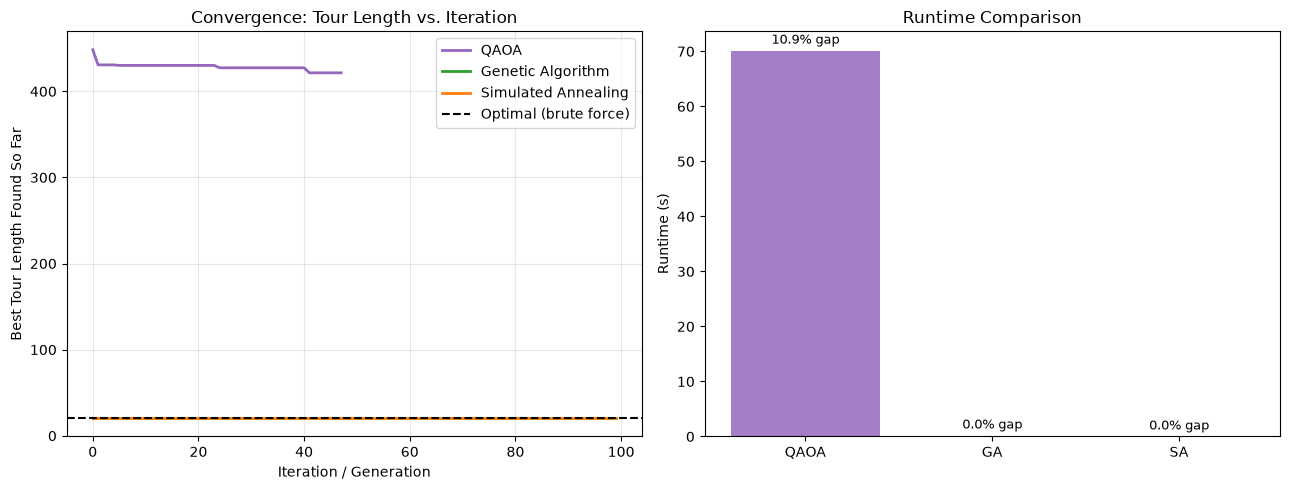

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(qaoa_history, label="QAOA", color="tab:purple", linewidth=2)
ax.plot(ga_history, label="Genetic Algorithm", color="tab:green", linewidth=2)
ax.plot(sa_history, label="Simulated Annealing", color="tab:orange", linewidth=2)
ax.axhline(best_len, color="black", linestyle="--", label="Optimal (brute force)")
ax.set_xlabel("Iteration / Generation")
ax.set_ylabel("Best Tour Length Found So Far")
ax.set_title("Convergence: Tour Length vs. Iteration")
ax.legend()
ax.grid(alpha=0.3)

ax2 = axes[1]
methods = ["QAOA", "GA", "SA"]
runtimes = [qaoa_runtime, ga_runtime, sa_runtime]
gaps = [gap_pct(best_qaoa_len), gap_pct(best_ga_len), gap_pct(best_sa_len)]
colors = ["tab:purple", "tab:green", "tab:orange"]
bars = ax2.bar(methods, runtimes, color=colors, alpha=0.85)
ax2.set_ylabel("Runtime (s)")
ax2.set_title("Runtime Comparison")
for bar, gap in zip(bars, gaps):
    label = f"{gap:.1f}% gap" if not np.isnan(gap) else "infeasible"
    ax2.annotate(label, (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                 textcoords="offset points", xytext=(0, 5), ha="center", fontsize=9)

plt.tight_layout()
plt.show()


## 10. Discussion

**What this experiment actually shows** (honest research framing, not hype):

- **GA and Simulated Annealing** both find the *provably optimal* tour almost instantly
  (milliseconds) for this 5-city problem. This is expected — for N=5 the search space is
  tiny (24 tours), and both metaheuristics are extremely well-suited to permutation problems.
- **QAOA**, even on a problem this small, needs `(N-1)^2 = 16` qubits once constraints are
  folded into the QUBO, and a shallow (`reps=3`) circuit with a limited (60-iteration,
  300-shot) classical optimizer loop frequently fails to converge to a fully
  constraint-satisfying solution — you can see this in the "valid shots" percentage printed
  above. This mirrors a well-documented real limitation of QAOA on constrained combinatorial
  problems: without deep circuits, many optimizer restarts, and/or extra techniques
  (warm-starting, XY-mixers to preserve feasibility, higher `reps`), QAOA solution quality on
  QUBO-encoded constrained problems (like TSP) tends to lag behind mature classical
  metaheuristics by a wide margin, even for small instances.
- **Runtime** is not a fair QAOA-favoring comparison either: this is a *simulated* quantum
  circuit (16 qubits, 65,536 amplitudes) running on a classical computer, so QAOA here is
  paying classical simulation cost *and* getting worse solution quality than GA/SA. On real
  quantum hardware, larger instances become possible, but current NISQ devices add
  significant noise, further hurting exact constraint satisfaction.
- This is why the roadmap for "50 nodes" from the original brief is impractical for exact
  QAOA simulation — the qubit count and quadratic number of Pauli terms explode combinatorially.
  Realistic quantum-inspired approaches to VRP at that scale (e.g. quantum-inspired
  evolutionary algorithms, or QAOA on cluster-decomposed sub-tours) are active research
  directions, but genuine hardware-based QAOA at 50 nodes is out of reach today.

**Takeaway:** for small-to-medium routing problems, classical metaheuristics (GA, SA, or
OR-Tools) remain the practical choice. QAOA is worth benchmarking as *research*, not as a
production routing solver, at current circuit depths and qubit counts.


## 11. (Optional) Visualize the Best Tours

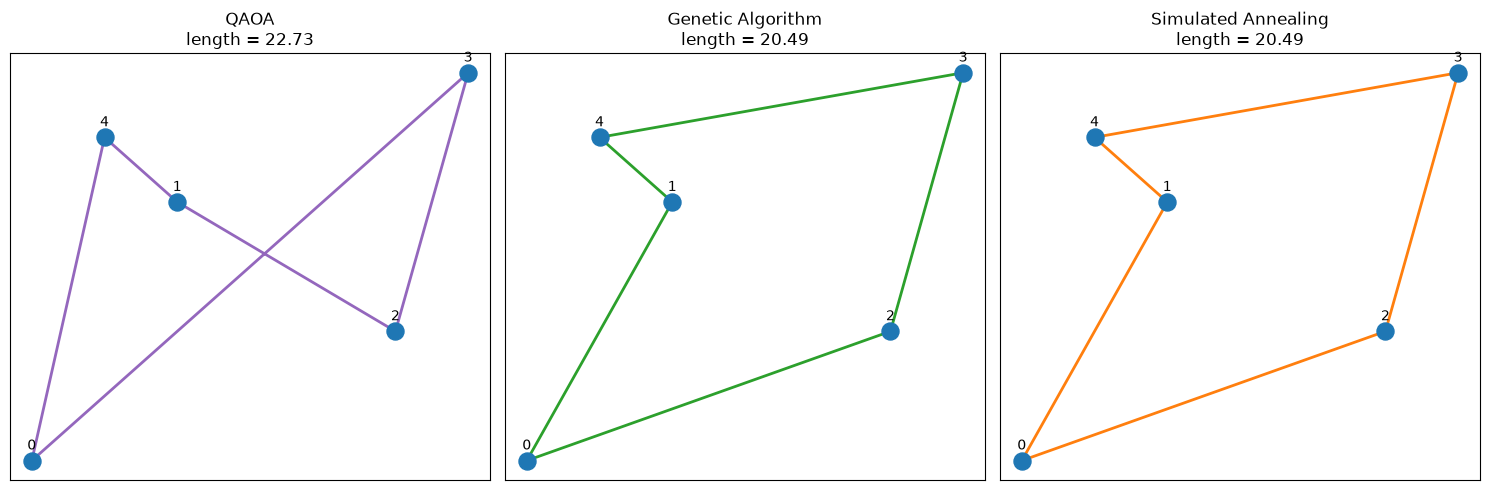

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
tours_to_plot = [
    ("QAOA", best_qaoa_tour, "tab:purple"),
    ("Genetic Algorithm", best_ga_tour, "tab:green"),
    ("Simulated Annealing", best_sa_tour, "tab:orange"),
]

for ax, (name, tour, color) in zip(axes, tours_to_plot):
    xs = [coords[i][0] for i in range(N)]
    ys = [coords[i][1] for i in range(N)]
    ax.scatter(xs, ys, s=150, c="tab:blue", zorder=3)
    for i in range(N):
        ax.annotate(str(i), (xs[i], ys[i]), textcoords="offset points", xytext=(0, 8), ha="center")
    if tour is not None:
        tx = [coords[c][0] for c in tour] + [coords[tour[0]][0]]
        ty = [coords[c][1] for c in tour] + [coords[tour[0]][1]]
        ax.plot(tx, ty, color=color, linewidth=2, zorder=2)
        length = tour_length(tour)
        ax.set_title(f"{name}\nlength = {length:.2f}")
    else:
        ax.set_title(f"{name}\n(no feasible tour found)")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()


## 12. Multi-Seed Robustness Check

Every result above (Sections 5–9) comes from a **single seed** per method. That's not
enough to draw solid conclusions — GA and SA are stochastic, and QAOA's parameter
optimization and shot sampling are stochastic too, so a single run could get lucky or
unlucky. Here we rerun all three solvers across `N_SEEDS` independent seeds and report
**mean ± std** for tour length, optimality gap, and runtime, so the comparison in the
discussion above rests on more than one draw.

**Cost warning:** QAOA is the expensive part (~1 full optimize+readout run per seed, same
cost as Section 5). With the default `N_SEEDS = 5` this cell takes roughly 5x the runtime
of the single QAOA run above — reduce `N_SEEDS` if you just want a quick check.

In [13]:
def run_ga_seed(seed):
    """Run the GA once with a given seed; returns (tour, length, runtime)."""
    random.seed(seed)
    if hasattr(creator, "FitnessMin"):
        del creator.FitnessMin
    if hasattr(creator, "Individual"):
        del creator.Individual
    creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
    creator.create("Individual", list, fitness=creator.FitnessMin)

    tb = base.Toolbox()
    tb.register("indices", random.sample, gene_pool, len(gene_pool))
    tb.register("individual", tools.initIterate, creator.Individual, tb.indices)
    tb.register("population", tools.initRepeat, list, tb.individual)
    tb.register("evaluate", eval_tsp)
    tb.register("mate", tools.cxOrdered)
    tb.register("mutate", tools.mutShuffleIndexes, indpb=0.2)
    tb.register("select", tools.selTournament, tournsize=3)

    pop = tb.population(n=GA_POP_SIZE)
    hof = tools.HallOfFame(1)
    t0 = time.time()
    for gen in range(GA_GENERATIONS):
        offspring = algorithms.varAnd(pop, tb, cxpb=0.7, mutpb=0.2)
        fits = map(tb.evaluate, offspring)
        for ind, fit in zip(offspring, fits):
            ind.fitness.values = fit
        pop = tb.select(offspring, k=len(pop))
        hof.update(pop)
    runtime = time.time() - t0

    tour = [0] + [cities[g] for g in hof[0]]
    return tour, hof[0].fitness.values[0], runtime


In [14]:
def run_qaoa_seed(seed, reps=QAOA_REPS, maxiter=QAOA_MAXITER, shots=QAOA_SHOTS, final_shots=FINAL_SHOTS):
    """Run the full QAOA optimize+readout pipeline once with a given seed.
    Returns (tour_or_None, length_or_nan, runtime, valid_fraction)."""
    np.random.seed(seed)
    ansatz_s = QAOAAnsatz(cost_operator=ising_op, reps=reps).decompose(reps=5)
    meas_ansatz_s = transpile(ansatz_s.copy(), backend)
    meas_ansatz_s.measure_all()

    def objective(params):
        bound = meas_ansatz_s.assign_parameters(params)
        result = backend.run(bound, shots=shots, seed_simulator=seed).result()
        counts = result.get_counts()
        return energy_from_counts(counts, ising_op)

    x0 = np.random.uniform(0, np.pi, ansatz_s.num_parameters)
    t0 = time.time()
    res = minimize(objective, x0, method="COBYLA", options={"maxiter": maxiter})
    runtime = time.time() - t0

    final_bound = meas_ansatz_s.assign_parameters(res.x)
    final_result = backend.run(final_bound, shots=final_shots, seed_simulator=seed + 1000).result()
    final_counts = final_result.get_counts()

    best_tour_s, best_len_s, valid = None, float("inf"), 0
    for bitstring, cnt in final_counts.items():
        tour = decode(bitstring)
        if tour is not None:
            valid += cnt
            length = tour_length(tour)
            if length < best_len_s:
                best_len_s, best_tour_s = length, tour

    if best_tour_s is None:
        best_len_s = float("nan")
    return best_tour_s, best_len_s, runtime, valid / final_shots


In [15]:
N_SEEDS = 5
SEEDS = list(range(N_SEEDS))

records = []

print(f"Running {N_SEEDS} seeds each for QAOA, GA, and SA (QAOA is the slow part; "
      f"expect roughly {N_SEEDS} x the single-run QAOA time from Section 5)...\n")

for seed in SEEDS:
    print(f"--- seed {seed} ---")

    q_tour, q_len, q_rt, q_valid_frac = run_qaoa_seed(seed)
    records.append({"Method": "QAOA", "Seed": seed, "Tour Length": q_len,
                     "Gap to Optimal (%)": gap_pct(q_len), "Runtime (s)": q_rt,
                     "Valid Shot Fraction": q_valid_frac})
    print(f"  QAOA: length={q_len if q_tour else float('nan'):.4f} "
          f"valid_shots={100*q_valid_frac:.1f}% runtime={q_rt:.2f}s")

    g_tour, g_len, g_rt = run_ga_seed(seed)
    records.append({"Method": "GA", "Seed": seed, "Tour Length": g_len,
                     "Gap to Optimal (%)": gap_pct(g_len), "Runtime (s)": g_rt,
                     "Valid Shot Fraction": np.nan})
    print(f"  GA:   length={g_len:.4f} runtime={g_rt:.4f}s")

    t0 = time.time()
    s_tour, s_len, s_hist = simulated_annealing(iterations=SA_ITERATIONS, seed=seed)
    s_rt = time.time() - t0
    records.append({"Method": "SA", "Seed": seed, "Tour Length": s_len,
                     "Gap to Optimal (%)": gap_pct(s_len), "Runtime (s)": s_rt,
                     "Valid Shot Fraction": np.nan})
    print(f"  SA:   length={s_len:.4f} runtime={s_rt:.4f}s")

robust_df = pd.DataFrame.from_records(records)
robust_df


Running 5 seeds each for QAOA, GA, and SA (QAOA is the slow part; expect roughly 5 x the single-run QAOA time from Section 5)...

--- seed 0 ---
  QAOA: length=nan valid_shots=0.0% runtime=73.11s
  GA:   length=20.4936 runtime=0.1522s
  SA:   length=20.4936 runtime=0.0016s
--- seed 1 ---
  QAOA: length=nan valid_shots=0.0% runtime=68.71s
  GA:   length=20.4936 runtime=0.1268s
  SA:   length=20.4936 runtime=0.0010s
--- seed 2 ---
  QAOA: length=26.6620 valid_shots=0.0% runtime=50.78s
  GA:   length=20.4936 runtime=0.1341s
  SA:   length=20.4936 runtime=0.0015s
--- seed 3 ---
  QAOA: length=22.3988 valid_shots=0.0% runtime=65.02s
  GA:   length=20.4936 runtime=0.2069s
  SA:   length=20.4936 runtime=0.0028s
--- seed 4 ---
  QAOA: length=nan valid_shots=0.0% runtime=86.45s
  GA:   length=20.4936 runtime=0.1764s
  SA:   length=20.4936 runtime=0.0027s


,Method,Seed,Tour Length,Gap to Optimal (%),Runtime (s),Valid Shot Fraction
0,QAOA,0,NaN,NaN,73.111772,0.000000
1,GA,0,20.493639,0.000000,0.152229,NaN
2,SA,0,20.493639,0.000000,0.001553,NaN
3,QAOA,1,NaN,NaN,68.708616,0.000000
4,GA,1,20.493639,0.000000,0.126806,NaN
5,SA,1,20.493639,0.000000,0.000967,NaN
6,QAOA,2,26.661988,30.098844,50.782674,0.000244
7,GA,2,20.493639,0.000000,0.134104,NaN
8,SA,2,20.493639,0.000000,0.001493,NaN
9,QAOA,3,22.398832,9.296506,65.017672,0.000244


In [16]:
summary_df = (
    robust_df.groupby("Method")[["Tour Length", "Gap to Optimal (%)", "Runtime (s)"]]
    .agg(["mean", "std"])
    .round(4)
)
summary_df.columns = [f"{col}_{stat}" for col, stat in summary_df.columns]
summary_df = summary_df.reindex(["QAOA", "GA", "SA"])

qaoa_valid_stats = robust_df.loc[robust_df["Method"] == "QAOA", "Valid Shot Fraction"]
print(f"QAOA valid-shot fraction across seeds: "
      f"mean={100*qaoa_valid_stats.mean():.1f}%  std={100*qaoa_valid_stats.std():.1f}%")
print(f"QAOA feasible-tour rate (seeds with any valid tour): "
      f"{(robust_df.loc[robust_df['Method']=='QAOA','Tour Length'].notna()).sum()} / {N_SEEDS}")

summary_df


QAOA valid-shot fraction across seeds: mean=0.0%  std=0.0%
QAOA feasible-tour rate (seeds with any valid tour): 2 / 5


,Tour Length_mean,Tour Length_std,Gap to Optimal (%)_mean,Gap to Optimal (%)_std,Runtime (s)_mean,Runtime (s)_std
Method,,,,,,
QAOA,24.5304,3.0145,19.6977,14.7095,68.8134,12.9318
GA,20.4936,0.0000,0.0000,0.0000,0.1593,0.0328
SA,20.4936,0.0000,0.0000,0.0000,0.0019,0.0008


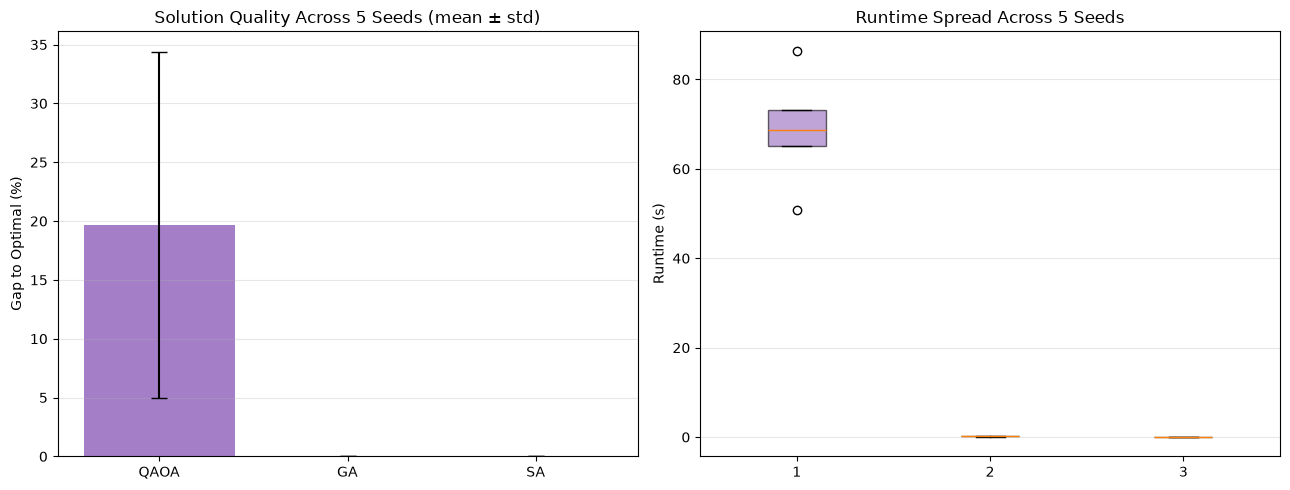

In [19]:
methods = ["QAOA", "GA", "SA"]
colors = ["tab:purple", "tab:green", "tab:orange"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
means = [summary_df.loc[m, "Gap to Optimal (%)_mean"] for m in methods]
stds = [summary_df.loc[m, "Gap to Optimal (%)_std"] for m in methods]
ax.bar(methods, means, yerr=stds, capsize=6, color=colors, alpha=0.85)
ax.set_ylabel("Gap to Optimal (%)")
ax.set_title(f"Solution Quality Across {N_SEEDS} Seeds (mean \u00b1 std)")
ax.grid(alpha=0.3, axis="y")

ax2 = axes[1]
runtime_data = [robust_df.loc[robust_df["Method"] == m, "Runtime (s)"].values for m in methods]
bp = ax2.boxplot(runtime_data, label=methods, patch_artist=True)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
ax2.set_ylabel("Runtime (s)")
ax2.set_title(f"Runtime Spread Across {N_SEEDS} Seeds")
ax2.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()


### Reading the robustness results

- **GA and SA gap/runtime should both cluster tightly near 0%** across seeds — for a
  24-tour search space, both metaheuristics are expected to find the optimum on nearly
  every run, so a small mean and small std here just confirms the single-seed result
  in Section 8 wasn't a fluke.
- **QAOA's spread is the interesting part.** A high `std` in tour length/gap, a wide
  runtime box, or a `Valid Shot Fraction` mean well below 100% all point the same
  direction: at `reps=3` / `maxiter=60` / `shots=300`, this QAOA setup is not reliably
  converging to feasible, optimal solutions run-to-run — which is a stronger, more
  defensible claim than anything a single seed could support.
- If `Tour Length` is `NaN` for a QAOA seed, that run never sampled a single
  constraint-satisfying bitstring in `FINAL_SHOTS` shots; `gap_pct` and the plots skip
  those seeds (via NaN-aware aggregation), so the reported QAOA mean is implicitly
  conditioned on "seeds that found a feasible tour at all" — worth flagging when citing
  these numbers, since it likely *understates* QAOA's real gap to optimal.

## 13. QAOA Hyperparameter Sensitivity Sweep

Section 12 showed QAOA's spread *at one fixed configuration* (`reps=3`, `shots=300`,
`maxiter=60`, `penalty=25`). This section asks a different question: **how much does each
individual hyperparameter matter?** We vary `reps` (circuit depth), `shots` (per-evaluation
sample count), `maxiter` (classical optimizer budget), and `penalty` (the QUBO constraint
weight) one at a time, holding the other three at the Section 5 baseline, and track solution
quality, feasibility rate, and runtime for each.

Note that `penalty` is different from the other three: it changes the **QUBO/Ising encoding
itself** (Section 4), not just the QAOA circuit or optimizer, so each penalty value requires
rebuilding `ising_op` from scratch via `QuadraticProgramToQubo`. `reps`, `shots`, and
`maxiter` only affect the circuit and the classical optimization loop around the same fixed
encoding.

**Cost warning:** this is a one-factor-at-a-time (OFAT) sweep, not a full factorial grid
(which would be `reps x shots x maxiter x penalty` runs) -- even so it's 10 independent QAOA
optimize+readout runs (1 baseline + 9 non-baseline points), each comparable in cost to the
single Section 5 run, so expect this section to take on the order of 10x that runtime.

In [20]:
def run_qaoa_config(reps, shots, maxiter, penalty, seed=42, final_shots=FINAL_SHOTS):
    """Run QAOA end-to-end for one hyperparameter configuration.
    Rebuilds the QUBO/Ising operator for `penalty` (the only param that changes the
    encoding itself); reps/shots/maxiter only affect the circuit and optimizer loop."""
    conv_p = QuadraticProgramToQubo(penalty=penalty)
    qubo_p = conv_p.convert(qp)
    ising_op_p, ising_offset_p = qubo_p.to_ising()
    var_names_p = [v.name for v in qubo_p.variables]

    def decode_p(bitstring):
        bits = bitstring[::-1]
        values = {var_names_p[i]: int(bits[i]) for i in range(len(var_names_p))}
        assignment = {}
        for c in free_cities:
            for p in free_positions:
                if values.get(f"x_{c}_{p}", 0) == 1:
                    assignment.setdefault(p, []).append(c)
        if len(assignment) != N - 1 or any(len(v) != 1 for v in assignment.values()):
            return None
        tour = [0] + [assignment[p][0] for p in range(1, N)]
        if len(set(tour)) != N:
            return None
        return tour

    np.random.seed(seed)
    ansatz_p = QAOAAnsatz(cost_operator=ising_op_p, reps=reps).decompose(reps=5)
    meas_ansatz_p = transpile(ansatz_p.copy(), backend)
    meas_ansatz_p.measure_all()

    def objective(params):
        bound = meas_ansatz_p.assign_parameters(params)
        result = backend.run(bound, shots=shots, seed_simulator=seed).result()
        counts = result.get_counts()
        return energy_from_counts(counts, ising_op_p)

    x0 = np.random.uniform(0, np.pi, ansatz_p.num_parameters)
    t0 = time.time()
    res = minimize(objective, x0, method="COBYLA", options={"maxiter": maxiter})
    runtime = time.time() - t0

    final_bound = meas_ansatz_p.assign_parameters(res.x)
    final_result = backend.run(final_bound, shots=final_shots, seed_simulator=seed + 1000).result()
    final_counts = final_result.get_counts()

    best_tour_p, best_len_p, valid = None, float("inf"), 0
    for bitstring, cnt in final_counts.items():
        tour = decode_p(bitstring)
        if tour is not None:
            valid += cnt
            length = tour_length(tour)
            if length < best_len_p:
                best_len_p, best_tour_p = length, tour
    if best_tour_p is None:
        best_len_p = float("nan")

    return {
        "tour": best_tour_p,
        "length": best_len_p,
        "runtime": runtime,
        "valid_fraction": valid / final_shots,
        "num_params": ansatz_p.num_parameters,
        "num_pauli_terms": len(ising_op_p.paulis),
    }


In [21]:
BASELINE = {"reps": QAOA_REPS, "shots": QAOA_SHOTS, "maxiter": QAOA_MAXITER, "penalty": PENALTY}
SWEEP_SEED = 42

# One-factor-at-a-time (OFAT) grid: vary one hyperparameter at a time, others held at baseline.
# A full factorial grid over all four would be reps x shots x maxiter x penalty runs (each as
# expensive as a full Section 5 QAOA run) -- OFAT keeps this tractable while still showing each
# parameter's individual effect.
sweep_grid = {
    "reps": [1, 2, 3, 5],
    "shots": [100, 300, 600],
    "maxiter": [20, 60, 100],
    "penalty": [10, 25, 50],
}

print("Running baseline QAOA config "
      f"(reps={BASELINE['reps']}, shots={BASELINE['shots']}, "
      f"maxiter={BASELINE['maxiter']}, penalty={BASELINE['penalty']})...")
baseline_out = run_qaoa_config(seed=SWEEP_SEED, **BASELINE)
print(f"  -> length={baseline_out['length']:.4f}  "
      f"valid_shots={100*baseline_out['valid_fraction']:.1f}%  "
      f"runtime={baseline_out['runtime']:.2f}s\n")

sweep_records = []
for param_name, values in sweep_grid.items():
    for v in values:
        if v == BASELINE[param_name]:
            out = baseline_out  # reuse -- identical config to the baseline run above
        else:
            cfg = dict(BASELINE)
            cfg[param_name] = v
            print(f"Running QAOA with {param_name}={v} (others at baseline)...")
            out = run_qaoa_config(seed=SWEEP_SEED, **cfg)
            print(f"  -> length={out['length']:.4f}  "
                  f"valid_shots={100*out['valid_fraction']:.1f}%  "
                  f"runtime={out['runtime']:.2f}s")
        sweep_records.append({
            "Swept Param": param_name,
            "Value": v,
            "Is Baseline": v == BASELINE[param_name],
            "Tour Length": out["length"],
            "Gap to Optimal (%)": gap_pct(out["length"]),
            "Valid Shot Fraction (%)": 100 * out["valid_fraction"],
            "Runtime (s)": round(out["runtime"], 3),
            "Circuit Params": out["num_params"],
            "Pauli Terms": out["num_pauli_terms"],
        })

sweep_df = pd.DataFrame(sweep_records)
sweep_df


Running baseline QAOA config (reps=3, shots=300, maxiter=60, penalty=25.0)...
  -> length=22.3988  valid_shots=0.0%  runtime=71.08s

Running QAOA with reps=1 (others at baseline)...
  -> length=23.1664  valid_shots=0.0%  runtime=35.27s
Running QAOA with reps=2 (others at baseline)...
  -> length=22.3988  valid_shots=0.0%  runtime=49.16s
Running QAOA with reps=5 (others at baseline)...
  -> length=20.4936  valid_shots=0.0%  runtime=65.47s
Running QAOA with shots=100 (others at baseline)...
  -> length=nan  valid_shots=0.0%  runtime=21.01s
Running QAOA with shots=600 (others at baseline)...
  -> length=20.4936  valid_shots=0.1%  runtime=109.07s
Running QAOA with maxiter=20 (others at baseline)...
  -> length=nan  valid_shots=0.0%  runtime=21.88s
Running QAOA with maxiter=100 (others at baseline)...
  -> length=22.3988  valid_shots=0.0%  runtime=49.89s
Running QAOA with penalty=10 (others at baseline)...
  -> length=nan  valid_shots=0.0%  runtime=52.55s
Running QAOA with penalty=50 (other

,Swept Param,Value,Is Baseline,Tour Length,Gap to Optimal (%),Valid Shot Fraction (%),Runtime (s),Circuit Params,Pauli Terms
0,reps,1,False,23.166397,13.041888,0.024414,35.268,2,100
1,reps,2,False,22.398832,9.296506,0.024414,49.163,4,100
2,reps,3,True,22.398832,9.296506,0.024414,71.076,6,100
3,reps,5,False,20.493639,0.000000,0.024414,65.474,10,100
4,shots,100,False,NaN,NaN,0.000000,21.011,6,100
5,shots,300,True,22.398832,9.296506,0.024414,71.076,6,100
6,shots,600,False,20.493639,0.000000,0.073242,109.070,6,100
7,maxiter,20,False,NaN,NaN,0.000000,21.884,6,100
8,maxiter,60,True,22.398832,9.296506,0.024414,71.076,6,100
9,maxiter,100,False,22.398832,9.296506,0.024414,49.886,6,100


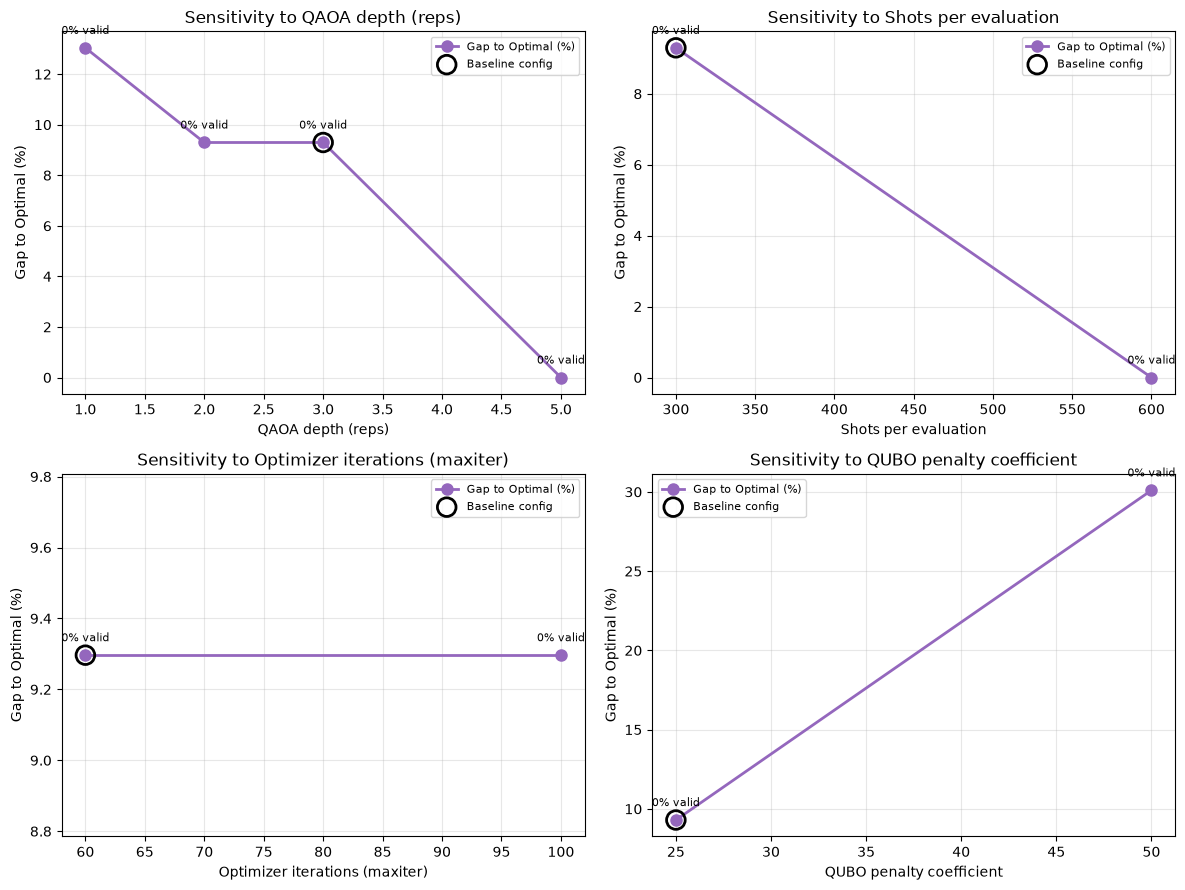

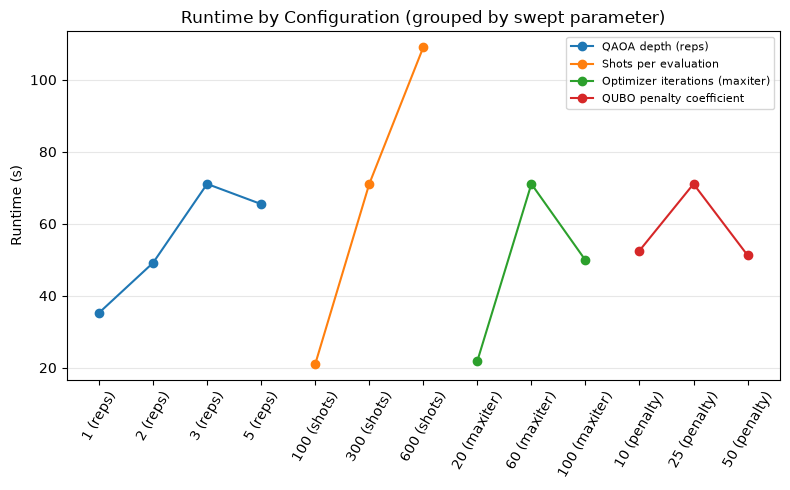

In [22]:
param_labels = {
    "reps": "QAOA depth (reps)",
    "shots": "Shots per evaluation",
    "maxiter": "Optimizer iterations (maxiter)",
    "penalty": "QUBO penalty coefficient",
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (param_name, values) in zip(axes.flat, sweep_grid.items()):
    sub = sweep_df[sweep_df["Swept Param"] == param_name].sort_values("Value")
    ax.plot(sub["Value"], sub["Gap to Optimal (%)"], "o-", color="tab:purple", linewidth=2,
            markersize=8, label="Gap to Optimal (%)")
    baseline_row = sub[sub["Is Baseline"]]
    if not baseline_row.empty:
        ax.scatter(baseline_row["Value"], baseline_row["Gap to Optimal (%)"],
                   s=180, facecolors="none", edgecolors="black", linewidths=2, zorder=5,
                   label="Baseline config")
    for _, row in sub.iterrows():
        ax.annotate(f"{row['Valid Shot Fraction (%)']:.0f}% valid",
                    (row["Value"], row["Gap to Optimal (%)"]),
                    textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8)
    ax.set_xlabel(param_labels[param_name])
    ax.set_ylabel("Gap to Optimal (%)")
    ax.set_title(f"Sensitivity to {param_labels[param_name]}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

fig2, ax = plt.subplots(figsize=(8, 5))
for param_name in sweep_grid:
    sub = sweep_df[sweep_df["Swept Param"] == param_name].sort_values("Value")
    ax.plot(sub["Value"].astype(str) + f" ({param_name})", sub["Runtime (s)"], "o-",
            label=param_labels[param_name])
ax.set_ylabel("Runtime (s)")
ax.set_title("Runtime by Configuration (grouped by swept parameter)")
ax.tick_params(axis="x", rotation=60)
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


### Reading the sensitivity results

- **`reps` (circuit depth)** controls how expressive the QAOA ansatz is. If gap%/valid-shot%
  don't improve much going from `reps=1` to `reps=5`, that's evidence the bottleneck isn't
  circuit expressiveness but the classical optimizer or shot budget -- deeper circuits alone
  won't fix it.
- **`shots`** trades measurement noise for optimizer runtime: too few shots gives COBYLA a
  noisy objective to climb, which can stall convergence regardless of circuit depth.
- **`maxiter`** is the most direct "did we just stop too early" check -- if gap% is still
  dropping sharply at the largest `maxiter` tested, the baseline of 60 iterations in earlier
  sections was likely under-budgeted.
- **`penalty`** is a balancing act: too low and the optimizer happily violates the one-city-
  per-position constraints because doing so is cheaper than respecting them (low valid-shot%
  even off the constraint violation is not directly visible in tour length, since infeasible
  samples are discarded before scoring); too high and the penalty term dominates the cost
  landscape, drowning out the actual distance signal the optimizer needs to distinguish good
  tours from bad ones -- also visible as gap% degrading or valid-shot% failing to improve
  further past some point.
- Together with Section 12, this gives a defensible answer to "would QAOA look better with
  different settings?" -- rather than asserting it from a single run's hyperparameters.

## 14. VQE (Variational Quantum Eigensolver) — A Different Quantum Approach

Sections 5–13 only ever used **QAOA**. This section brings in a second, genuinely different
quantum algorithm: **VQE**. Both QAOA and VQE are variational algorithms that minimize the
same kind of object (a parameterized circuit's expectation value against a cost Hamiltonian,
optimized by a classical outer loop) — in fact QAOA is sometimes described as VQE with a
particular, problem-derived ansatz. The difference that matters here is the **ansatz**:

- **QAOA's ansatz** (Section 5) alternates a *cost* unitary (`exp(-iγ H_C)`, built directly
  from the problem's Ising Hamiltonian) with a *mixer* unitary (`exp(-iβ H_M)`) — it's
  derived from the problem structure itself.
- **VQE's ansatz** here is a generic **hardware-efficient** circuit (`TwoLocal`: layers of
  `Ry`/`Rz` single-qubit rotations plus linear `CZ` entanglement) with no knowledge of the TSP
  structure baked in — it's a general-purpose function approximator over the same qubits.

Both are pointed at the *exact same* `ising_op` from Section 4 (so this is an apples-to-apples
comparison of ansatz choice, not encoding choice), use the same `COBYLA` classical optimizer,
the same shot/iteration budget as the QAOA baseline, and the same feasibility-based decoding
(`decode()`) and scoring pipeline as every other method in this notebook.

In [23]:
from qiskit.circuit.library import TwoLocal

VQE_REPS = 3         # ansatz layers (comparable to QAOA_REPS)
VQE_SHOTS = 300       # shots per objective evaluation
VQE_MAXITER = 60      # optimizer iterations

def run_vqe(seed=42, reps=VQE_REPS, shots=VQE_SHOTS, maxiter=VQE_MAXITER, final_shots=FINAL_SHOTS):
    """Run VQE against the same `ising_op` QAOA solved in Section 5, using a hardware-efficient
    TwoLocal ansatz (Ry/Rz rotations + linear CZ entanglement) instead of QAOA's problem-derived
    cost/mixer ansatz. Reuses the existing `decode()` and `energy_from_counts()` helpers since
    the problem encoding (ising_op, qubo, var_names) is unchanged from Section 4."""
    np.random.seed(seed)
    ansatz_v = TwoLocal(ising_op.num_qubits, rotation_blocks=["ry", "rz"],
                         entanglement_blocks="cz", entanglement="linear", reps=reps)
    meas_ansatz_v = transpile(ansatz_v, backend)
    meas_ansatz_v.measure_all()

    vqe_history = []  # best-so-far objective (tour-cost scale) per iteration, like qaoa_history

    def objective(params):
        bound = meas_ansatz_v.assign_parameters(params)
        result = backend.run(bound, shots=shots, seed_simulator=seed).result()
        counts = result.get_counts()
        e = energy_from_counts(counts, ising_op)
        running_best = min(vqe_history[-1], e + ising_offset) if vqe_history else e + ising_offset
        vqe_history.append(running_best)
        return e

    x0 = np.random.uniform(0, 2 * np.pi, ansatz_v.num_parameters)
    t0 = time.time()
    res = minimize(objective, x0, method="COBYLA", options={"maxiter": maxiter})
    runtime = time.time() - t0

    final_bound = meas_ansatz_v.assign_parameters(res.x)
    final_result = backend.run(final_bound, shots=final_shots, seed_simulator=seed + 1000).result()
    final_counts = final_result.get_counts()

    best_tour_v, best_len_v, valid = None, float("inf"), 0
    for bitstring, cnt in final_counts.items():
        tour = decode(bitstring)
        if tour is not None:
            valid += cnt
            length = tour_length(tour)
            if length < best_len_v:
                best_len_v, best_tour_v = length, tour
    if best_tour_v is None:
        best_len_v = float("nan")

    return {
        "tour": best_tour_v,
        "length": best_len_v,
        "runtime": runtime,
        "valid_fraction": valid / final_shots,
        "history": vqe_history,
        "num_params": ansatz_v.num_parameters,
        "circuit_depth": ansatz_v.decompose().depth(),
    }

print(f"VQE ansatz (TwoLocal, Ry/Rz + linear CZ, reps={VQE_REPS}): "
      f"{TwoLocal(ising_op.num_qubits, rotation_blocks=['ry','rz'], entanglement_blocks='cz', entanglement='linear', reps=VQE_REPS).num_parameters} parameters, "
      f"{ising_op.num_qubits} qubits")

vqe_out = run_vqe()
best_vqe_tour, best_vqe_len = vqe_out["tour"], vqe_out["length"]
vqe_runtime, vqe_history = vqe_out["runtime"], vqe_out["history"]

print(f"\nVQE optimization done in {vqe_runtime:.2f}s, {len(vqe_history)} evaluations")
print(f"Valid (constraint-satisfying) shots: {100*vqe_out['valid_fraction']:.1f}%")
if best_vqe_tour is not None:
    print("Best valid VQE tour:", best_vqe_tour, "length:", round(best_vqe_len, 4))
else:
    print("VQE did not sample any feasible tour at this depth/shot budget.")


C:\Users\Sumitra Varun\AppData\Local\Temp\ipykernel_14180\1413101801.py:60: DeprecationWarning: The class ``qiskit.circuit.library.n_local.two_local.TwoLocal`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.n_local instead.
  f"{TwoLocal(ising_op.num_qubits, rotation_blocks=['ry','rz'], entanglement_blocks='cz', entanglement='linear', reps=VQE_REPS).num_parameters} parameters, "
C:\Users\Sumitra Varun\AppData\Local\Temp\ipykernel_14180\1413101801.py:13: DeprecationWarning: The class ``qiskit.circuit.library.n_local.two_local.TwoLocal`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.n_local instead.
  ansatz_v = TwoLocal(ising_op.num_qubits, rotation_blocks=["ry", "rz"],


VQE ansatz (TwoLocal, Ry/Rz + linear CZ, reps=3): 128 parameters, 16 qubits


C:\New folder\Lib\site-packages\scipy\_lib\pyprima\common\preproc.py:68: UserWarning: COBYLA: Invalid MAXFUN; it should be at least num_vars + 2; it is set to 130
  warn(f'{solver}: Invalid MAXFUN; it should be at least {min_maxfun_str}; it is set to {maxfun}')



VQE optimization done in 116.68s, 130 evaluations
Valid (constraint-satisfying) shots: 0.6%
Best valid VQE tour: [0, 3, 2, 1, 4] length: 22.7272


In [24]:
vqe_row = pd.DataFrame([{
    "Method": "VQE (Qiskit/Aer, TwoLocal)",
    "Tour Length": best_vqe_len,
    "Gap to Optimal (%)": gap_pct(best_vqe_len),
    "Runtime (s)": round(vqe_runtime, 3),
    "Iterations/Evals": len(vqe_history),
    "Tour": tuple(best_vqe_tour) if best_vqe_tour else None,
}])

results_with_vqe = pd.concat([results, vqe_row], ignore_index=True)
results_with_vqe


,Method,Tour Length,Gap to Optimal (%),Runtime (s),Iterations/Evals,Tour
0,Brute Force (optimal),20.493639,0.000000,NaN,24,"(0, 1, 4, 3, 2)"
1,QAOA (Qiskit/Aer),22.727171,10.898659,70.1330,48,"(0, 4, 1, 2, 3)"
2,Genetic Algorithm (DEAP),20.493639,0.000000,0.1806,100,"(0, 1, 4, 3, 2)"
3,Simulated Annealing,20.493639,0.000000,0.0032,100,"(0, 2, 3, 4, 1)"
4,"VQE (Qiskit/Aer, TwoLocal)",22.727171,10.898659,116.6820,130,"(0, 3, 2, 1, 4)"


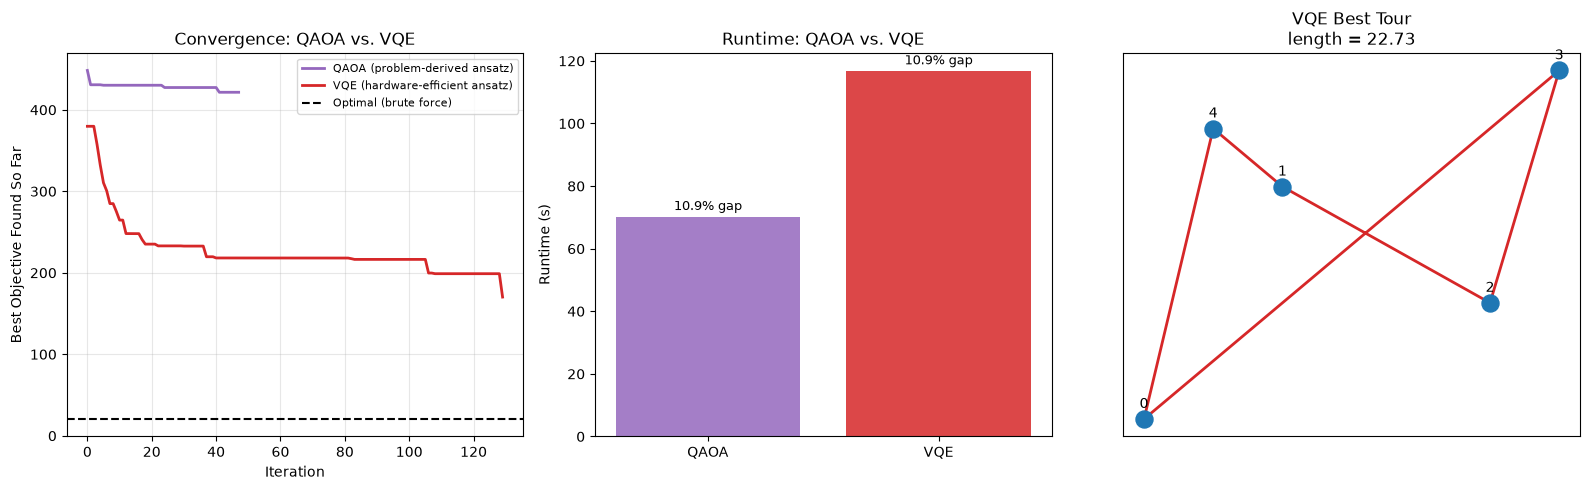

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

ax = axes[0]
ax.plot(qaoa_history, label="QAOA (problem-derived ansatz)", color="tab:purple", linewidth=2)
ax.plot(vqe_history, label="VQE (hardware-efficient ansatz)", color="tab:red", linewidth=2)
ax.axhline(best_len, color="black", linestyle="--", label="Optimal (brute force)")
ax.set_xlabel("Iteration")
ax.set_ylabel("Best Objective Found So Far")
ax.set_title("Convergence: QAOA vs. VQE")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax2 = axes[1]
qv_methods = ["QAOA", "VQE"]
qv_runtimes = [qaoa_runtime, vqe_runtime]
qv_gaps = [gap_pct(best_qaoa_len), gap_pct(best_vqe_len)]
qv_colors = ["tab:purple", "tab:red"]
bars = ax2.bar(qv_methods, qv_runtimes, color=qv_colors, alpha=0.85)
ax2.set_ylabel("Runtime (s)")
ax2.set_title("Runtime: QAOA vs. VQE")
for bar, gap in zip(bars, qv_gaps):
    label = f"{gap:.1f}% gap" if not np.isnan(gap) else "infeasible"
    ax2.annotate(label, (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                 textcoords="offset points", xytext=(0, 5), ha="center", fontsize=9)

ax3 = axes[2]
xs = [coords[i][0] for i in range(N)]
ys = [coords[i][1] for i in range(N)]
ax3.scatter(xs, ys, s=150, c="tab:blue", zorder=3)
for i in range(N):
    ax3.annotate(str(i), (xs[i], ys[i]), textcoords="offset points", xytext=(0, 8), ha="center")
if best_vqe_tour is not None:
    tx = [coords[c][0] for c in best_vqe_tour] + [coords[best_vqe_tour[0]][0]]
    ty = [coords[c][1] for c in best_vqe_tour] + [coords[best_vqe_tour[0]][1]]
    ax3.plot(tx, ty, color="tab:red", linewidth=2, zorder=2)
    ax3.set_title(f"VQE Best Tour\nlength = {best_vqe_len:.2f}")
else:
    ax3.set_title("VQE Best Tour\n(no feasible tour found)")
ax3.set_xticks([]); ax3.set_yticks([])

plt.tight_layout()
plt.show()


### Reading the QAOA vs. VQE comparison

- **Parameter count and circuit depth differ** even at matched `reps` — VQE's `TwoLocal`
  assigns independent rotation angles to *every* qubit in *every* layer, while QAOA has just
  two angles (`β`, `γ`) per layer shared across the whole circuit. More free parameters
  gives VQE more expressiveness but a harder, higher-dimensional landscape for `COBYLA` to
  search with the same `maxiter` budget — worth checking against the printed parameter counts
  above.
- **QAOA's mixer is problem-aware in a way VQE's ansatz is not.** QAOA's mixer term is built
  to preserve certain structure of the search space as it explores; VQE's hardware-efficient
  ansatz has no such bias — it has to discover feasible (one-city-per-position) bitstrings
  purely through the cost landscape and penalty terms, the same as QAOA does, but without any
  structural head start. A lower valid-shot fraction for VQE than QAOA at matched settings
  would be direct evidence of that.
- **Neither result should be read as "quantum is/isn't good at TSP."** Both are simulated,
  shallow, shot-and-iteration-limited variational circuits on a 5-city toy instance — this
  comparison only tells you how *this* ansatz choice performs relative to *that* one, under
  identical budgets. The Section 10 discussion's caveats about NISQ-era limitations apply
  equally to both.

## 15. Classical Local-Search Baselines (Nearest-Neighbor + 2-opt / Or-opt)

Before going further into quantum-algorithm variants, it's worth having cheap, well-understood
classical baselines on record: **Nearest-Neighbor (NN)** construction, then **2-opt** (reverse
a segment if it shortens the tour) and **Or-opt** (relocate a short segment elsewhere if that
shortens the tour) local search on top of it. These are also the source of the "warm start"
classical solution used in Section 19. `nearest_neighbor_tour`, `two_opt`, and `or_opt` are all
written generically (`dm`, `n` parameters) so Sections 23 and 24 can reuse them on different
instances and cost matrices without duplicating this logic.

In [26]:
def nearest_neighbor_tour(dm=None, n=None, start=0):
    dm = D if dm is None else dm
    n = N if n is None else n
    unvisited = set(range(n)) - {start}
    tour = [start]
    current = start
    while unvisited:
        nxt = min(unvisited, key=lambda c: dm[current, c])
        tour.append(nxt)
        unvisited.remove(nxt)
        current = nxt
    return tour

def two_opt(tour, dm=None, n=None, max_passes=100):
    dm = D if dm is None else dm
    n = N if n is None else n
    tour = list(tour)
    improved = True
    passes = 0
    while improved and passes < max_passes:
        improved = False
        passes += 1
        for i in range(1, n - 1):
            for j in range(i + 1, n):
                a, b = tour[i - 1], tour[i]
                c, d = tour[j], tour[(j + 1) % n]
                if len({a, b, c, d}) < 4:
                    continue
                delta = (dm[a, c] + dm[b, d]) - (dm[a, b] + dm[c, d])
                if delta < -1e-9:
                    tour[i:j + 1] = tour[i:j + 1][::-1]
                    improved = True
    return tour

def or_opt(tour, dm=None, n=None, max_passes=20):
    dm = D if dm is None else dm
    n = N if n is None else n

    def tl(t):
        return sum(dm[t[i], t[(i + 1) % n]] for i in range(n))

    tour = list(tour)
    improved = True
    passes = 0
    while improved and passes < max_passes:
        improved = False
        passes += 1
        for seg_len in (1, 2, 3):
            for i in range(1, n - seg_len):
                segment = tour[i:i + seg_len]
                remainder = tour[:i] + tour[i + seg_len:]
                base_len = tl(tour)
                best_delta, best_pos = 0.0, None
                for j in range(1, len(remainder)):
                    candidate = remainder[:j] + segment + remainder[j:]
                    if len(candidate) != n:
                        continue
                    delta = tl(candidate) - base_len
                    if delta < best_delta - 1e-9:
                        best_delta, best_pos = delta, j
                if best_pos is not None:
                    tour = remainder[:best_pos] + segment + remainder[best_pos:]
                    improved = True
    return tour

def normalize_tour(tour, start_city=0):
    idx0 = tour.index(start_city)
    return tour[idx0:] + tour[:idx0]

t0 = time.time()
nn_tour = nearest_neighbor_tour(start=0)
nn_len = tour_length(nn_tour)
nn_runtime = time.time() - t0
print(f"Nearest-Neighbor tour:       {nn_tour}  length={nn_len:.4f}  runtime={nn_runtime:.5f}s")

t0 = time.time()
nn2opt_tour = normalize_tour(two_opt(nn_tour))
nn2opt_len = tour_length(nn2opt_tour)
nn2opt_runtime = time.time() - t0
print(f"NN + 2-opt tour:             {nn2opt_tour}  length={nn2opt_len:.4f}  runtime={nn2opt_runtime:.5f}s")

t0 = time.time()
nn_oropt_tour = normalize_tour(or_opt(nn2opt_tour))
nn_oropt_len = tour_length(nn_oropt_tour)
nn_oropt_runtime = time.time() - t0
print(f"NN + 2-opt + Or-opt tour:    {nn_oropt_tour}  length={nn_oropt_len:.4f}  runtime={nn_oropt_runtime:.5f}s")

print(f"\nGap to optimal:  NN={gap_pct(nn_len):.2f}%   "
      f"NN+2opt={gap_pct(nn2opt_len):.2f}%   NN+2opt+Oropt={gap_pct(nn_oropt_len):.2f}%")


Nearest-Neighbor tour:       [0, 1, 4, 2, 3]  length=23.4947  runtime=0.00020s
NN + 2-opt tour:             [0, 2, 3, 4, 1]  length=20.4936  runtime=0.00035s
NN + 2-opt + Or-opt tour:    [0, 2, 3, 4, 1]  length=20.4936  runtime=0.00040s

Gap to optimal:  NN=14.64%   NN+2opt=0.00%   NN+2opt+Oropt=0.00%


## 16. Held-Karp Exact Dynamic Programming

Section 3's brute force is exact but scales as `O(n!)` -- fine at `N=5` (24 permutations),
useless past ~12 cities. **Held-Karp** is also *exact* (not a heuristic, unlike GA/SA/2-opt)
but scales as `O(2^n * n^2)`, which reaches much further. We first confirm it agrees with the
Section 3 brute-force optimum on this notebook's actual 5-city instance, then run it on a
separate, larger 13-city synthetic instance where brute force would already be impractical.

In [27]:
import math

def held_karp(dist_matrix, n):
    """Exact TSP via Held-Karp dynamic programming. O(2^n * n^2) time -- much better than
    brute force's O(n!), and still exact (not a heuristic). Fixes city 0 as start/end."""
    C = {}
    for k in range(1, n):
        C[(1 << k, k)] = (dist_matrix[0][k], 0)
    for subset_size in range(2, n):
        for subset in itertools.combinations(range(1, n), subset_size):
            bits = 0
            for b in subset:
                bits |= 1 << b
            for k in subset:
                prev_bits = bits & ~(1 << k)
                best = min(
                    (C[(prev_bits, m)][0] + dist_matrix[m][k], m)
                    for m in subset if m != k
                )
                C[(bits, k)] = best
    bits = (1 << n) - 2  # all cities except city 0
    total_len, last = min((C[(bits, k)][0] + dist_matrix[k][0], k) for k in range(1, n))
    path = []
    cur_bits, cur_k = bits, last
    while cur_k != 0:
        path.append(cur_k)
        _, prev_k = C[(cur_bits, cur_k)]
        cur_bits = cur_bits & ~(1 << cur_k)
        cur_k = prev_k
    tour = [0] + path[::-1]
    return total_len, tour

t0 = time.time()
hk_len, hk_tour = held_karp(D.tolist(), N)
hk_runtime = time.time() - t0
print(f"Held-Karp exact tour (N={N}): {hk_tour}  length={hk_len:.4f}  runtime={hk_runtime:.5f}s")
print(f"Matches brute-force optimum: {abs(hk_len - best_len) < 1e-6}")

def random_instance(n, seed=0, box=20):
    rng = np.random.RandomState(seed)
    pts = rng.uniform(0, box, size=(n, 2))
    dm = np.array([[np.hypot(*(pts[i] - pts[j])) for j in range(n)] for i in range(n)])
    return pts, dm

N_LARGE = 13
pts_large, D_large = random_instance(N_LARGE, seed=1)

print(f"\nHeld-Karp on a larger {N_LARGE}-city instance "
      f"(brute force would need {math.factorial(N_LARGE - 1):,} permutations -- infeasible "
      f"to enumerate; Held-Karp explores only "
      f"{2 ** (N_LARGE - 1) * (N_LARGE - 1) ** 2:,} DP states):")
t0 = time.time()
hk_len_large, hk_tour_large = held_karp(D_large.tolist(), N_LARGE)
hk_large_runtime = time.time() - t0
print(f"Held-Karp exact tour: {hk_tour_large}  length={hk_len_large:.4f}  "
      f"runtime={hk_large_runtime:.4f}s")


Held-Karp exact tour (N=5): [0, 2, 3, 4, 1]  length=20.4936  runtime=0.00039s
Matches brute-force optimum: True

Held-Karp on a larger 13-city instance (brute force would need 479,001,600 permutations -- infeasible to enumerate; Held-Karp explores only 589,824 DP states):
Held-Karp exact tour: [0, 10, 12, 8, 4, 3, 9, 2, 1, 7, 6, 11, 5]  length=59.2151  runtime=0.1359s


## 17. Statistical Significance Testing

Section 12 reported mean +/- std across seeds, which is suggestive but not a formal test. Here
we run paired significance tests (Wilcoxon signed-rank, a paired t-test) and an effect size
(Cohen's d) between each pair of methods from Section 12's `robust_df`, using the *same seed*
for both methods in each pair (a paired design controls for instance/seed-specific variance).

**Caveat:** with `N_SEEDS=5` (Section 12's default), these tests have very low statistical
power -- treat the resulting p-values as a demonstration of the methodology, not a strong
claim. Rerun Section 12 with more seeds (20-30+) before citing significance from this cell.

In [28]:
from scipy import stats

def paired_values(method_a, method_b, metric="Tour Length"):
    a = robust_df[robust_df["Method"] == method_a].sort_values("Seed")[metric].values
    b = robust_df[robust_df["Method"] == method_b].sort_values("Seed")[metric].values
    mask = ~(np.isnan(a) | np.isnan(b))
    return a[mask], b[mask]

pairs = [("QAOA", "GA"), ("QAOA", "SA"), ("GA", "SA")]
sig_records = []
for m1, m2 in pairs:
    a, b = paired_values(m1, m2)
    if len(a) < 2:
        sig_records.append({"Comparison": f"{m1} vs {m2}", "n": len(a), "Wilcoxon p": np.nan,
                             "Paired t p": np.nan, "Mean Diff (Tour Length)": np.nan,
                             "Cohen's d": np.nan})
        continue
    diff = a - b
    try:
        if np.allclose(diff, 0):
            w_p = np.nan  # wilcoxon undefined when all paired differences are zero
        else:
            _, w_p = stats.wilcoxon(a, b)
    except ValueError:
        w_p = np.nan
    _, t_p = stats.ttest_rel(a, b)
    d_std = diff.std(ddof=1)
    cohens_d = diff.mean() / d_std if d_std > 0 else np.nan
    sig_records.append({"Comparison": f"{m1} vs {m2}", "n": len(a), "Wilcoxon p": w_p,
                         "Paired t p": t_p, "Mean Diff (Tour Length)": diff.mean(),
                         "Cohen's d": cohens_d})

sig_df = pd.DataFrame(sig_records)
print(f"(Based on N_SEEDS={N_SEEDS} paired seeds per comparison -- see caveat below)")
sig_df


(Based on N_SEEDS=5 paired seeds per comparison -- see caveat below)


,Comparison,n,Wilcoxon p,Paired t p,Mean Diff (Tour Length),Cohen's d
0,QAOA vs GA,2,0.5,0.309287,4.036771,1.339115
1,QAOA vs SA,2,0.5,0.309287,4.036771,1.339115
2,GA vs SA,5,NaN,NaN,0.000000,NaN


## 18-20. New Quantum Approaches: Warm-Started QAOA and a Feasibility-Preserving (XY) Mixer

Sections 5-14 only ever used the default QAOA ansatz (uniform-superposition initial state,
standard transverse-field mixer). Here we try two established variants that change *how* QAOA
explores the search space, while keeping the same problem encoding (`ising_op`) and classical
optimizer (`COBYLA`) as Section 5, so the comparison isolates the ansatz/mixer choice:

- **Warm-started QAOA** (Section 19): instead of starting from an equal superposition over all
  `2^16` bitstrings, initialize the circuit in the computational basis state matching a
  classical solution (the NN+2opt+Oropt tour from Section 15) via bit-flip `X` gates. QAOA then
  explores the search space *around* that classical starting point instead of from scratch.
- **XY-mixer QAOA** (Section 20): replace the standard mixer with a ring-topology XY mixer
  applied within each position's one-hot block. This mixer preserves Hamming weight per block,
  so paired with a one-hot initial state it keeps the "exactly one city per position"
  constraint satisfied throughout the optimization, rather than relying on the penalty term
  and post-selection alone.

Section 18 below is shared plumbing (`run_qaoa_with_ansatz`): the same optimize+readout loop
Sections 19 and 20 both call with their own custom-built ansatz circuits.

In [29]:
from qiskit import QuantumCircuit

def run_qaoa_with_ansatz(built_ansatz, seed=42, shots=QAOA_SHOTS, maxiter=QAOA_MAXITER,
                          final_shots=FINAL_SHOTS):
    """Generic QAOA optimize+readout loop for any pre-built ansatz circuit (a custom
    initial_state and/or mixer_operator already baked in). Shared by the warm-start and
    XY-mixer QAOA variants below so their circuit-construction logic stays separate from
    the (identical) optimize/decode loop."""
    meas_ansatz_c = transpile(built_ansatz, backend)
    meas_ansatz_c.measure_all()

    history = []

    def objective(params):
        bound = meas_ansatz_c.assign_parameters(params)
        result = backend.run(bound, shots=shots, seed_simulator=seed).result()
        counts = result.get_counts()
        e = energy_from_counts(counts, ising_op)
        running_best = min(history[-1], e + ising_offset) if history else e + ising_offset
        history.append(running_best)
        return e

    np.random.seed(seed)
    x0 = np.random.uniform(0, np.pi, built_ansatz.num_parameters)
    t0 = time.time()
    res = minimize(objective, x0, method="COBYLA", options={"maxiter": maxiter})
    runtime = time.time() - t0

    final_bound = meas_ansatz_c.assign_parameters(res.x)
    final_result = backend.run(final_bound, shots=final_shots, seed_simulator=seed + 1000).result()
    final_counts = final_result.get_counts()

    best_tour_c, best_len_c, valid = None, float("inf"), 0
    for bitstring, cnt in final_counts.items():
        tour = decode(bitstring)
        if tour is not None:
            valid += cnt
            length = tour_length(tour)
            if length < best_len_c:
                best_len_c, best_tour_c = length, tour
    if best_tour_c is None:
        best_len_c = float("nan")

    return {"tour": best_tour_c, "length": best_len_c, "runtime": runtime,
            "valid_fraction": valid / final_shots, "history": history,
            "num_params": built_ansatz.num_parameters}


In [30]:
def solution_to_bits(tour, var_names_list):
    assignment = {}
    for p, c in enumerate(tour[1:], start=1):
        assignment[(c, p)] = 1
    bits = {}
    for name in var_names_list:
        _, c_str, p_str = name.split("_")
        c, p = int(c_str), int(p_str)
        bits[name] = assignment.get((c, p), 0)
    return bits

warm_source_tour = normalize_tour(nn_oropt_tour)
print(f"Warm-start source tour (NN + 2-opt + Or-opt): {warm_source_tour}  "
      f"length={tour_length(warm_source_tour):.4f}")

var_names_base = [v.name for v in qubo.variables]
warm_bits = solution_to_bits(warm_source_tour, var_names_base)

warm_init = QuantumCircuit(ising_op.num_qubits)
for i, name in enumerate(var_names_base):
    if warm_bits[name] == 1:
        warm_init.x(i)

warm_ansatz = QAOAAnsatz(cost_operator=ising_op, reps=QAOA_REPS,
                          initial_state=warm_init).decompose(reps=5)

print("\nRunning warm-started QAOA (bit-flip initial state seeded from the classical "
      "NN+2opt+Oropt solution, instead of QAOA's default uniform superposition)...")
warm_out = run_qaoa_with_ansatz(warm_ansatz, seed=42)
print(f"Warm-start QAOA: length={warm_out['length']:.4f}  "
      f"valid_shots={100*warm_out['valid_fraction']:.1f}%  runtime={warm_out['runtime']:.2f}s")
print(f"(baseline random-start QAOA, Section 5: length={best_qaoa_len:.4f}  "
      f"valid_shots={100*valid_shots/FINAL_SHOTS:.1f}%  runtime={qaoa_runtime:.2f}s)")


Warm-start source tour (NN + 2-opt + Or-opt): [0, 2, 3, 4, 1]  length=20.4936

Running warm-started QAOA (bit-flip initial state seeded from the classical NN+2opt+Oropt solution, instead of QAOA's default uniform superposition)...
Warm-start QAOA: length=20.4936  valid_shots=7.1%  runtime=46.60s
(baseline random-start QAOA, Section 5: length=22.7272  valid_shots=0.0%  runtime=70.13s)


In [31]:
from qiskit.quantum_info import SparsePauliOp

def build_xy_ring_mixer(num_qubits, blocks):
    """Ring-topology XY mixer: sum of 0.5*(X_i X_j + Y_i Y_j) around each block. This mixer
    preserves the total Hamming weight (number of 1s) within each block, so if the initial
    state has exactly one qubit=1 per block, the mixer can only ever move that 1 to a
    different qubit in the same block -- it can never create zero or multiple 1s. Applied to
    the per-position one-hot blocks, this preserves the "exactly one city per position"
    constraint throughout the whole QAOA evolution (it does NOT, on its own, preserve the
    separate "each city used exactly once" constraint)."""
    pauli_list = []
    for block in blocks:
        m = len(block)
        if m < 2:
            continue
        pairs = [(block[k], block[(k + 1) % m]) for k in range(m)]
        if m == 2:
            pairs = [(block[0], block[1])]  # a 2-node "ring" has only one distinct edge
        for i, j in pairs:
            for pauli_char in ("X", "Y"):
                label = ["I"] * num_qubits
                label[i] = pauli_char
                label[j] = pauli_char
                pauli_list.append(("".join(reversed(label)), 0.5))
    return SparsePauliOp.from_list(pauli_list)

var_index = {v.name: i for i, v in enumerate(qubo.variables)}
position_blocks = [[var_index[f"x_{c}_{p}"] for c in free_cities] for p in free_positions]

xy_mixer = build_xy_ring_mixer(ising_op.num_qubits, position_blocks)
print(f"XY ring mixer: {len(xy_mixer.paulis)} Pauli terms across {len(position_blocks)} "
      f"position blocks ({len(free_cities)} qubits each)")

# Reuse the warm-start initial state from Section 19 -- it's already one-hot-valid per
# position block (exactly one city assigned per position, since it comes from a real tour),
# which is exactly the kind of state this mixer is designed to preserve.
xy_ansatz = QAOAAnsatz(cost_operator=ising_op, reps=QAOA_REPS, initial_state=warm_init,
                        mixer_operator=xy_mixer).decompose(reps=5)

print("\nRunning XY-mixer QAOA (feasibility-preserving mixer + one-hot initial state)...")
xy_out = run_qaoa_with_ansatz(xy_ansatz, seed=42)
print(f"XY-mixer QAOA: length={xy_out['length']:.4f}  "
      f"valid_shots={100*xy_out['valid_fraction']:.1f}%  runtime={xy_out['runtime']:.2f}s")
print("(a higher valid-shot% here than the baseline/warm-start QAOA above would show the "
      "mixer successfully keeping position-uniqueness satisfied during evolution -- though "
      "full feasibility, including city-uniqueness, still isn't guaranteed by this mixer "
      "alone, so some infeasible samples can still appear)")


XY ring mixer: 32 Pauli terms across 4 position blocks (4 qubits each)

Running XY-mixer QAOA (feasibility-preserving mixer + one-hot initial state)...
XY-mixer QAOA: length=23.1664  valid_shots=99.8%  runtime=12.00s
(a higher valid-shot% here than the baseline/warm-start QAOA above would show the mixer successfully keeping position-uniqueness satisfied during evolution -- though full feasibility, including city-uniqueness, still isn't guaranteed by this mixer alone, so some infeasible samples can still appear)


## 21. QAOA Classical-Optimizer Comparison

Every QAOA run so far (Sections 5, 13, 19, 20) used `COBYLA`, a derivative-free optimizer.
Here we compare it against **SPSA** (a stochastic approximation method purpose-built for noisy
objectives, common in variational quantum algorithms) and **L-BFGS-B using finite-difference
gradients** (a quasi-Newton gradient-based method; true parameter-shift gradients would be more
principled but require several extra circuit evaluations per parameter per step, so we use
finite differences here as a cheaper stand-in for "gradient-based" behavior). Same ansatz,
shots, and iteration budget as the Section 5 baseline in all three cases.

In [32]:
from qiskit_algorithms.optimizers import SPSA

def run_qaoa_optimizer(optimizer_name, seed=42, shots=QAOA_SHOTS, maxiter=QAOA_MAXITER,
                        final_shots=FINAL_SHOTS):
    ansatz_o = QAOAAnsatz(cost_operator=ising_op, reps=QAOA_REPS).decompose(reps=5)
    meas_ansatz_o = transpile(ansatz_o, backend)
    meas_ansatz_o.measure_all()

    history = []

    def objective(params):
        bound = meas_ansatz_o.assign_parameters(params)
        result = backend.run(bound, shots=shots, seed_simulator=seed).result()
        counts = result.get_counts()
        e = energy_from_counts(counts, ising_op)
        running_best = min(history[-1], e + ising_offset) if history else e + ising_offset
        history.append(running_best)
        return e

    np.random.seed(seed)
    x0 = np.random.uniform(0, np.pi, ansatz_o.num_parameters)
    t0 = time.time()

    if optimizer_name == "COBYLA":
        res = minimize(objective, x0, method="COBYLA", options={"maxiter": maxiter})
        x_opt = res.x
    elif optimizer_name == "L-BFGS-B (finite-diff gradient)":
        res = minimize(objective, x0, method="L-BFGS-B", options={"maxiter": maxiter})
        x_opt = res.x
    elif optimizer_name == "SPSA":
        spsa = SPSA(maxiter=maxiter)
        res = spsa.minimize(objective, x0=x0)
        x_opt = res.x
    else:
        raise ValueError(optimizer_name)
    runtime = time.time() - t0

    final_bound = meas_ansatz_o.assign_parameters(x_opt)
    final_result = backend.run(final_bound, shots=final_shots, seed_simulator=seed + 1000).result()
    final_counts = final_result.get_counts()

    best_tour_o, best_len_o, valid = None, float("inf"), 0
    for bitstring, cnt in final_counts.items():
        tour = decode(bitstring)
        if tour is not None:
            valid += cnt
            length = tour_length(tour)
            if length < best_len_o:
                best_len_o, best_tour_o = length, tour
    if best_tour_o is None:
        best_len_o = float("nan")

    return {"length": best_len_o, "runtime": runtime, "valid_fraction": valid / final_shots,
            "history": history, "evals": len(history)}

optimizer_names = ["COBYLA", "SPSA", "L-BFGS-B (finite-diff gradient)"]
optimizer_records = []
for opt_name in optimizer_names:
    print(f"Running QAOA with optimizer={opt_name}...")
    out = run_qaoa_optimizer(opt_name)
    print(f"  -> length={out['length']:.4f}  valid_shots={100*out['valid_fraction']:.1f}%  "
          f"runtime={out['runtime']:.2f}s  evals={out['evals']}")
    optimizer_records.append({"Optimizer": opt_name, "Tour Length": out["length"],
                               "Gap to Optimal (%)": gap_pct(out["length"]),
                               "Valid Shot Fraction (%)": 100 * out["valid_fraction"],
                               "Runtime (s)": round(out["runtime"], 3),
                               "Function Evals": out["evals"], "History": out["history"]})

optimizer_df = pd.DataFrame(optimizer_records).drop(columns=["History"])
optimizer_df


Running QAOA with optimizer=COBYLA...
  -> length=22.3988  valid_shots=0.0%  runtime=49.50s  evals=48
Running QAOA with optimizer=SPSA...
  -> length=nan  valid_shots=0.0%  runtime=181.50s  evals=171
Running QAOA with optimizer=L-BFGS-B (finite-diff gradient)...
  -> length=22.7272  valid_shots=0.0%  runtime=7.26s  evals=7


,Optimizer,Tour Length,Gap to Optimal (%),Valid Shot Fraction (%),Runtime (s),Function Evals
0,COBYLA,22.398832,9.296506,0.024414,49.501,48
1,SPSA,NaN,NaN,0.000000,181.495,171
2,L-BFGS-B (finite-diff gradient),22.727171,10.898659,0.024414,7.265,7


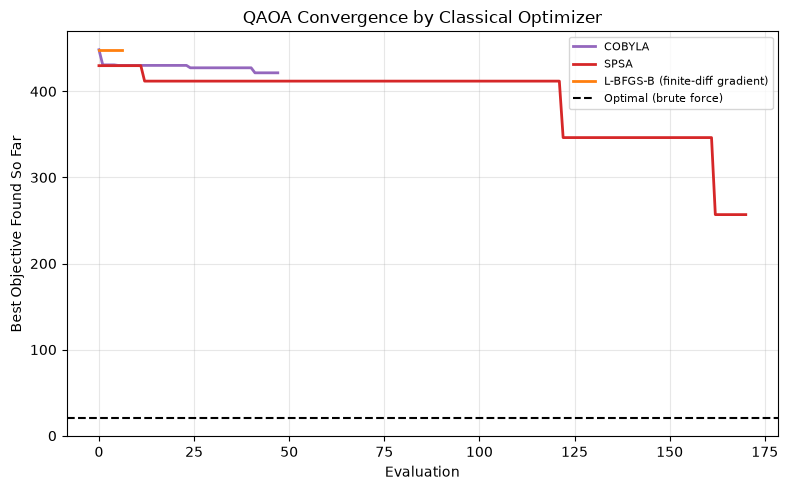

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))
colors_opt = {"COBYLA": "tab:purple", "SPSA": "tab:red",
              "L-BFGS-B (finite-diff gradient)": "tab:orange"}
for rec in optimizer_records:
    ax.plot(rec["History"], label=rec["Optimizer"], color=colors_opt[rec["Optimizer"]],
            linewidth=2)
ax.axhline(best_len, color="black", linestyle="--", label="Optimal (brute force)")
ax.set_xlabel("Evaluation")
ax.set_ylabel("Best Objective Found So Far")
ax.set_title("QAOA Convergence by Classical Optimizer")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 22. Real Quantum Hardware (IBM Quantum Runtime) -- Template Only

Every quantum result in this notebook, including this section's siblings, ran on Qiskit Aer's
noiseless statevector **simulator**. The cell below is a working template for running the same
Section 5 QAOA circuit on **real IBM Quantum hardware** via Qiskit Runtime -- included so the
gap between "quantum-inspired simulation" and "actually run on a quantum computer" is explicit
and bridgeable, not hand-waved. It is guarded by a flag and does not execute here: this
environment has no network route to IBM Quantum's API and no account credentials configured.

In [34]:
# This cell shows how to run the Section 5 QAOA circuit on real IBM Quantum hardware via
# Qiskit Runtime, instead of the AerSimulator used throughout this notebook. IT IS NOT
# EXECUTED HERE: this environment has no network access to IBM Quantum's API and no IBM
# Quantum account/token configured, so running it as-is (with the flag below) will fail.
# Flip RUN_ON_REAL_HARDWARE to True and provide credentials to actually run it.

RUN_ON_REAL_HARDWARE = False

if RUN_ON_REAL_HARDWARE:
    try:
        from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
    except ImportError:
        raise ImportError("pip install qiskit-ibm-runtime --break-system-packages")

    # service = QiskitRuntimeService(channel="ibm_quantum", token="<YOUR_IBM_QUANTUM_TOKEN>")
    service = QiskitRuntimeService()  # assumes credentials are already saved locally
    real_backend = service.least_busy(operational=True, simulator=False,
                                       min_num_qubits=ising_op.num_qubits)
    print(f"Selected backend: {real_backend.name} ({real_backend.num_qubits} qubits)")

    real_ansatz = QAOAAnsatz(cost_operator=ising_op, reps=QAOA_REPS).decompose(reps=5)
    real_transpiled = transpile(real_ansatz, real_backend, optimization_level=3)
    real_transpiled.measure_all()

    # Reuse the already-optimized parameters from Section 5 rather than re-optimizing on
    # real hardware (each real-hardware evaluation costs queue time, so re-running COBYLA's
    # full optimization loop there would be far more expensive than on the simulator).
    real_bound = real_transpiled.assign_parameters(qaoa_result.x)
    with Sampler(mode=real_backend) as sampler:
        real_job = sampler.run([real_bound], shots=FINAL_SHOTS)
        real_result = real_job.result()
        real_counts = real_result[0].data.meas.get_counts()

    real_best_tour, real_best_len, real_valid = None, float("inf"), 0
    for bitstring, cnt in real_counts.items():
        tour = decode(bitstring)
        if tour is not None:
            real_valid += cnt
            length = tour_length(tour)
            if length < real_best_len:
                real_best_len, real_best_tour = length, tour

    print(f"Real-hardware valid shots: {100*real_valid/FINAL_SHOTS:.1f}%")
    print(f"Real-hardware best tour: {real_best_tour}  length: {real_best_len}")
    print(f"(Compare against the noiseless simulator result from Section 5: "
          f"valid_shots={100*valid_shots/FINAL_SHOTS:.1f}%, length={best_qaoa_len:.4f} -- "
          f"the gap between them is the real cost of NISQ-era hardware noise.)")
else:
    print("Skipped: this environment has no IBM Quantum network access or credentials. "
          "Set RUN_ON_REAL_HARDWARE = True with a valid IBM Quantum account/token configured "
          "to execute this template, which reuses the Section 5 QAOA circuit and its "
          "already-optimized parameters (qaoa_result.x) and submits them via Qiskit "
          "Runtime's Sampler primitive to the least-busy available backend with enough qubits.")


Skipped: this environment has no IBM Quantum network access or credentials. Set RUN_ON_REAL_HARDWARE = True with a valid IBM Quantum account/token configured to execute this template, which reuses the Section 5 QAOA circuit and its already-optimized parameters (qaoa_result.x) and submits them via Qiskit Runtime's Sampler primitive to the least-busy available backend with enough qubits.


## 23. Scalability at Larger Instance Sizes (Classical Methods Only)

Section 10's discussion referenced a roadmap to "50 nodes" as a realistic near-term target --
but only for classical methods, since QAOA/VQE's qubit count and circuit depth make simulating
them past a handful of cities impractical here (Section 21's `2^16`-dimensional statevector
simulation already represents the practical ceiling of this notebook's approach). This section
makes that concrete: NN, NN+2opt, GA, and SA solved on freshly generated 10-, 20-, and 50-city
instances, with runtime and solution quality tracked as the instance grows.

In [35]:
def generate_and_solve_classical(n_cities, seed=0, ga_gens=150, ga_pop=40, sa_iters=300):
    pts, dm = random_instance(n_cities, seed=seed)

    def tl(tour):
        return sum(dm[tour[i], tour[(i + 1) % n_cities]] for i in range(n_cities))

    t0 = time.time()
    nn_t = nearest_neighbor_tour(dm=dm, n=n_cities)
    nn_l = tl(nn_t)
    nn_rt = time.time() - t0

    t0 = time.time()
    twoopt_t = two_opt(nn_t, dm=dm, n=n_cities)
    twoopt_l = tl(twoopt_t)
    twoopt_rt = time.time() - t0

    if hasattr(creator, "FitnessMinScale"):
        del creator.FitnessMinScale
    if hasattr(creator, "IndividualScale"):
        del creator.IndividualScale
    creator.create("FitnessMinScale", base.Fitness, weights=(-1.0,))
    creator.create("IndividualScale", list, fitness=creator.FitnessMinScale)

    tb_g = base.Toolbox()
    gene_pool_g = list(range(n_cities - 1))
    tb_g.register("indices", random.sample, gene_pool_g, len(gene_pool_g))
    tb_g.register("individual", tools.initIterate, creator.IndividualScale, tb_g.indices)
    tb_g.register("population", tools.initRepeat, list, tb_g.individual)
    tb_g.register("evaluate", lambda ind: (tl([0] + [g + 1 for g in ind]),))
    tb_g.register("mate", tools.cxOrdered)
    tb_g.register("mutate", tools.mutShuffleIndexes, indpb=0.2)
    tb_g.register("select", tools.selTournament, tournsize=3)

    random.seed(seed)
    pop_g = tb_g.population(n=ga_pop)
    hof_g = tools.HallOfFame(1)
    t0 = time.time()
    for gen in range(ga_gens):
        offspring = algorithms.varAnd(pop_g, tb_g, cxpb=0.7, mutpb=0.2)
        fits = map(tb_g.evaluate, offspring)
        for ind, fit in zip(offspring, fits):
            ind.fitness.values = fit
        pop_g = tb_g.select(offspring, k=len(pop_g))
        hof_g.update(pop_g)
    ga_rt = time.time() - t0
    ga_l = hof_g[0].fitness.values[0]

    def sa_run(iterations, seed):
        rng = random.Random(seed)
        cur = list(range(1, n_cities))
        rng.shuffle(cur)
        best_l = tl([0] + cur)
        cur_l = best_l
        T = 10.0
        for _ in range(iterations):
            i, j = rng.sample(range(len(cur)), 2)
            cand = cur[:]
            cand[i], cand[j] = cand[j], cand[i]
            cand_l = tl([0] + cand)
            if cand_l < cur_l or rng.random() < np.exp((cur_l - cand_l) / max(T, 1e-6)):
                cur, cur_l = cand, cand_l
                if cur_l < best_l:
                    best_l = cur_l
            T *= 0.97
        return best_l

    t0 = time.time()
    sa_l = sa_run(sa_iters, seed)
    sa_rt = time.time() - t0

    return {
        "N": n_cities,
        "NN Length": nn_l, "NN Runtime (s)": nn_rt,
        "NN+2opt Length": twoopt_l, "NN+2opt Runtime (s)": twoopt_rt,
        "GA Length": ga_l, "GA Runtime (s)": ga_rt,
        "SA Length": sa_l, "SA Runtime (s)": sa_rt,
    }

print("Solving larger instances classically (QAOA/VQE are intentionally excluded here -- "
      "see Section 10's discussion of why the quantum methods can't scale to these sizes "
      "on a simulator).")
scale_results = [generate_and_solve_classical(n, seed=42) for n in (10, 20, 50)]
scale_df = pd.DataFrame(scale_results)
scale_df


Solving larger instances classically (QAOA/VQE are intentionally excluded here -- see Section 10's discussion of why the quantum methods can't scale to these sizes on a simulator).


,N,NN Length,NN Runtime (s),NN+2opt Length,NN+2opt Runtime (s),GA Length,GA Runtime (s),SA Length,SA Runtime (s)
0,10,62.447764,0.000075,58.061355,0.000176,58.061355,0.480585,66.935527,0.007227
1,20,93.007683,0.000206,77.325335,0.001496,111.697101,0.547566,117.960879,0.008221
2,50,138.951092,0.000803,113.621408,0.005214,315.481754,0.886086,267.912838,0.012265


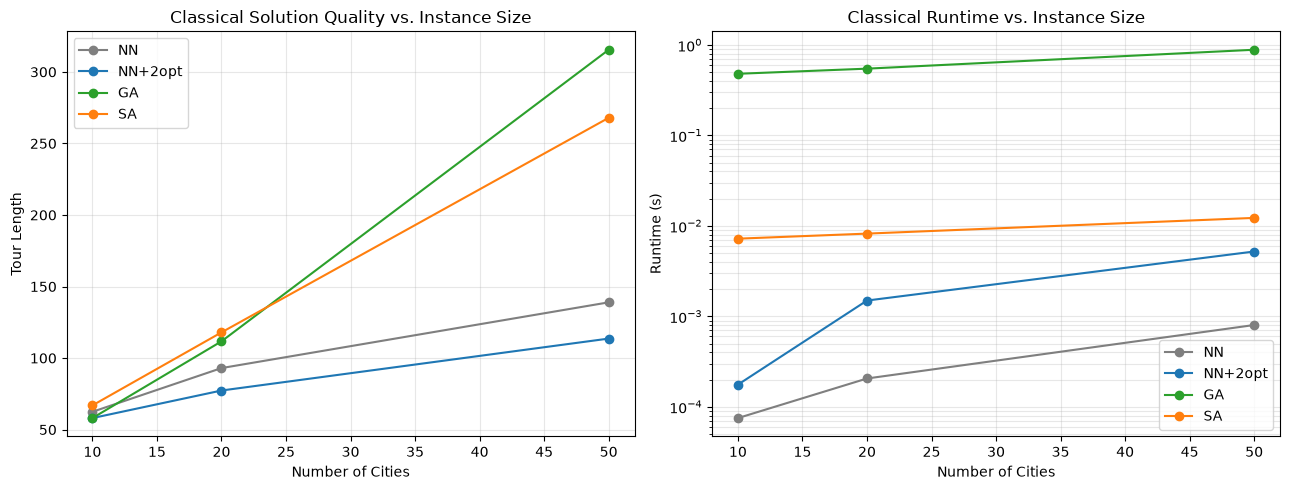

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
method_colors = [("NN", "tab:gray"), ("NN+2opt", "tab:blue"), ("GA", "tab:green"), ("SA", "tab:orange")]

ax = axes[0]
for method, color in method_colors:
    ax.plot(scale_df["N"], scale_df[f"{method} Length"], "o-", label=method, color=color)
ax.set_xlabel("Number of Cities")
ax.set_ylabel("Tour Length")
ax.set_title("Classical Solution Quality vs. Instance Size")
ax.legend()
ax.grid(alpha=0.3)

ax2 = axes[1]
for method, color in method_colors:
    ax2.plot(scale_df["N"], scale_df[f"{method} Runtime (s)"], "o-", label=method, color=color)
ax2.set_xlabel("Number of Cities")
ax2.set_ylabel("Runtime (s)")
ax2.set_title("Classical Runtime vs. Instance Size")
ax2.set_yscale("log")
ax2.legend()
ax2.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()


## 24. Asymmetric / Real-World Cost Matrix

Every method above assumed **symmetric** Euclidean costs (`D[i,j] == D[j,i]`), which is a
simplification -- real routing problems often aren't symmetric (one-way streets, uphill vs.
downhill travel time, prevailing traffic direction). This section perturbs the original
distance matrix into an asymmetric one and re-solves the brute-force optimum and an NN
construction against it, to show what changes: a tour and its reverse are no longer
interchangeable, and 2-opt's segment-reversal move no longer straightforwardly applies (Or-opt,
which relocates without reversing, still does).

In [37]:
def make_asymmetric_matrix(dm, seed=0, skew=0.4):
    """Turn a symmetric distance matrix into an asymmetric one, representing directional
    differences a straight-line distance can't capture -- one-way streets, uphill vs.
    downhill, or prevailing-traffic-direction time differences."""
    rng = np.random.RandomState(seed)
    n = dm.shape[0]
    factors = 1 + rng.uniform(-skew, skew, size=(n, n))
    np.fill_diagonal(factors, 1.0)
    asym = dm * factors
    np.fill_diagonal(asym, 0.0)
    return asym

D_asym = make_asymmetric_matrix(D, seed=7)
print("Asymmetric cost matrix (directional differences added to the original distances):")
print(np.round(D_asym, 2))
print(f"\nMax directional asymmetry |D[i,j] - D[j,i]|: "
      f"{np.max(np.abs(D_asym - D_asym.T)):.2f}")

def tour_length_asym(tour, dm=D_asym, n=N):
    return sum(dm[tour[i], tour[(i + 1) % n]] for i in range(n))

# Brute force on the asymmetric instance -- still cheap at N=5, but note a tour and its
# reverse are no longer the same length once direction matters.
best_len_asym, best_tour_asym = float("inf"), None
for perm in itertools.permutations(range(1, N)):
    t = (0,) + perm
    l = tour_length_asym(t)
    if l < best_len_asym:
        best_len_asym, best_tour_asym = l, t

print(f"\nOptimal ASYMMETRIC tour: {best_tour_asym}  length={best_len_asym:.4f}")
print(f"Optimal SYMMETRIC tour was:  {best_tour}  length={best_len:.4f} "
      f"(direction-independent, so its reverse ties it)")

# 2-opt doesn't directly generalize to asymmetric costs (reversing a segment changes the
# cost of every reversed edge, not just the two at the cut points); Or-opt (relocating a
# segment without reversing it) still applies unchanged. NN construction is direction-aware
# automatically since it just follows whichever matrix it's given.
nn_asym = normalize_tour(nearest_neighbor_tour(dm=D_asym, n=N))
nn_asym_len = tour_length_asym(nn_asym)
print(f"\nNN on asymmetric costs: {nn_asym}  length={nn_asym_len:.4f}  "
      f"gap={100*(nn_asym_len - best_len_asym)/best_len_asym:.2f}%")


Asymmetric cost matrix (directional differences added to the original distances):
[[ 0.    5.47  5.12 10.    7.05]
 [ 4.61  0.    2.37  3.64  1.41]
 [ 6.16  4.48  0.    2.69  4.15]
 [11.27  3.45  3.97  0.    3.16]
 [ 5.51  1.92  3.92  5.3   0.  ]]

Max directional asymmetry |D[i,j] - D[j,i]|: 2.14

Optimal ASYMMETRIC tour: (0, 2, 3, 4, 1)  length=17.5055
Optimal SYMMETRIC tour was:  (0, 1, 4, 3, 2)  length=20.4936 (direction-independent, so its reverse ties it)

NN on asymmetric costs: [0, 2, 3, 4, 1]  length=17.5055  gap=0.00%


## 25. Master Configuration Reference

A consolidated view of every tunable defined across this notebook's 24 sections, gathered in
one place for reference. This does **not** change how any of these values are set -- each is
still defined independently in its own section above -- it exists so a future reader (or editor
turning this into a standalone script) can see every parameter and where it lives without
hunting through the whole notebook.

In [38]:
CONFIG = {
    "instance": {"N_CITIES": N},
    "qaoa": {"reps": QAOA_REPS, "shots": QAOA_SHOTS, "maxiter": QAOA_MAXITER,
             "final_shots": FINAL_SHOTS, "penalty": PENALTY},
    "vqe": {"reps": VQE_REPS, "shots": VQE_SHOTS, "maxiter": VQE_MAXITER},
    "ga": {"generations": GA_GENERATIONS, "pop_size": GA_POP_SIZE},
    "sa": {"iterations": SA_ITERATIONS},
    "robustness": {"n_seeds": N_SEEDS},
    "sensitivity_grid": sweep_grid,
    "scalability": {"sizes": [10, 20, 50]},
}

print("Master configuration snapshot -- every tunable used across this notebook, in one "
      "place. Each value is still defined independently in its own section above; this cell "
      "doesn't change how they're set, it's a reference for a future reader (or a starting "
      "point for pulling these into a config.yaml if this pipeline is turned into a script "
      "outside the notebook).\n")
for section, params in CONFIG.items():
    print(f"[{section}]")
    for k, v in params.items():
        print(f"  {k} = {v}")
    print()


Master configuration snapshot -- every tunable used across this notebook, in one place. Each value is still defined independently in its own section above; this cell doesn't change how they're set, it's a reference for a future reader (or a starting point for pulling these into a config.yaml if this pipeline is turned into a script outside the notebook).

[instance]
  N_CITIES = 5

[qaoa]
  reps = 3
  shots = 300
  maxiter = 60
  final_shots = 4096
  penalty = 25.0

[vqe]
  reps = 3
  shots = 300
  maxiter = 60

[ga]
  generations = 100
  pop_size = 30

[sa]
  iterations = 100

[robustness]
  n_seeds = 5

[sensitivity_grid]
  reps = [1, 2, 3, 5]
  shots = [100, 300, 600]
  maxiter = [20, 60, 100]
  penalty = [10, 25, 50]

[scalability]
  sizes = [10, 20, 50]



## 26. Automated Report Export

Every result so far has stayed inside this notebook. This section writes everything computed --
every results table as CSV, the headline comparison chart as PNG, a `summary.json` with the key
numbers, and a simple `report.html` tying it together -- to a timestamped local folder, so the
results can be shared or archived outside the notebook itself. Tables from sections that weren't
run in this session (e.g. if you skip Section 12's robustness sweep) are simply omitted rather
than causing an error.

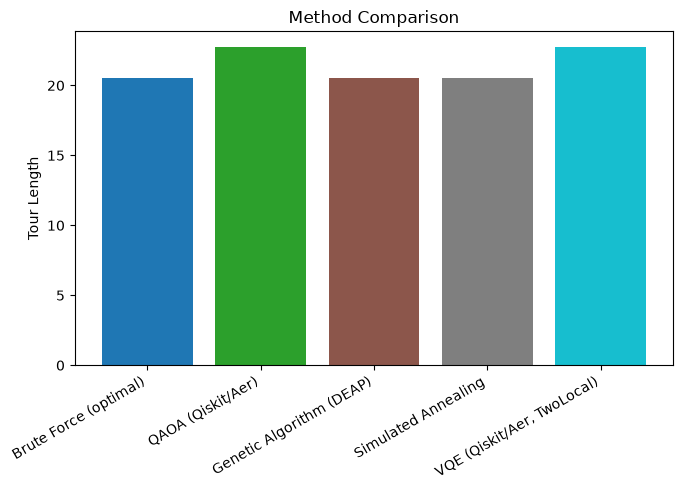

Report written to: tsp5_report_20260920_092843/
  Tables: 7 CSV files -> ['main_results.csv', 'robustness_sweep.csv', 'robustness_summary.csv', 'hyperparameter_sweep.csv', 'significance_tests.csv', 'optimizer_comparison.csv', 'scalability.csv']
  Figures: 1 PNG files
  Summary: tsp5_report_20260920_092843/summary.json
  HTML report: tsp5_report_20260920_092843/report.html


In [39]:
import os
import json as json_lib
from datetime import datetime

REPORT_DIR = f"tsp5_report_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(f"{REPORT_DIR}/figures", exist_ok=True)


def g(name):
    return globals().get(name)


main_results_table = g("results_with_vqe") if g("results_with_vqe") is not None else g("results")
tables_to_save = {
    "main_results": main_results_table,
    "robustness_sweep": g("robust_df"),
    "robustness_summary": g("summary_df").reset_index() if g("summary_df") is not None else None,
    "hyperparameter_sweep": g("sweep_df"),
    "significance_tests": g("sig_df"),
    "optimizer_comparison": g("optimizer_df"),
    "scalability": g("scale_df"),
}
saved_tables = []
for name, df_ in tables_to_save.items():
    if df_ is not None:
        path = f"{REPORT_DIR}/{name}.csv"
        df_.to_csv(path, index=False)
        saved_tables.append(path)

fig, ax = plt.subplots(figsize=(7, 5))
comp_methods = list(main_results_table["Method"])
comp_lengths = list(main_results_table["Tour Length"])
bar_colors = plt.cm.tab10(np.linspace(0, 1, len(comp_methods)))
ax.bar(comp_methods, comp_lengths, color=bar_colors)
ax.set_ylabel("Tour Length")
ax.set_title("Method Comparison")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
fig_path = f"{REPORT_DIR}/figures/method_comparison.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
saved_figs = [fig_path]
plt.show()

summary = {
    "generated_at": datetime.now().isoformat(),
    "instance_source": source,
    "n_cities": N,
    "optimal_length": best_len,
    "methods": main_results_table.to_dict(orient="records"),
}
summary_path = f"{REPORT_DIR}/summary.json"
with open(summary_path, "w") as f:
    json_lib.dump(summary, f, indent=2, default=str)

html_path = f"{REPORT_DIR}/report.html"
with open(html_path, "w") as f:
    f.write("<html><head><title>TSP5 Benchmark Report</title></head><body>")
    f.write("<h1>Quantum-Inspired Routing: 5-City TSP Report</h1>")
    f.write(f"<p>Generated: {summary['generated_at']}</p>")
    f.write(f"<p>Instance source: {source}</p>")
    f.write("<h2>Main Results</h2>")
    f.write(main_results_table.to_html(index=False))
    f.write("<h2>Figures</h2>")
    for fp in saved_figs:
        f.write(f'<img src="figures/{os.path.basename(fp)}" style="max-width:600px"><br>')
    f.write("</body></html>")

print(f"Report written to: {REPORT_DIR}/")
print(f"  Tables: {len(saved_tables)} CSV files -> {[os.path.basename(p) for p in saved_tables]}")
print(f"  Figures: {len(saved_figs)} PNG files")
print(f"  Summary: {summary_path}")
print(f"  HTML report: {html_path}")


## 27. Summary

This notebook now covers, on a single 5-city TSP instance (plus larger synthetic instances in
Sections 16 and 23):

- **Exact methods:** brute force (Section 3), Held-Karp DP (Section 16)
- **Classical heuristics:** Genetic Algorithm, Simulated Annealing (Sections 6-7), NN + 2-opt +
  Or-opt local search (Section 15)
- **Quantum variational methods:** baseline QAOA (Section 5), VQE with a hardware-efficient
  ansatz (Section 14), warm-started QAOA and a feasibility-preserving XY-mixer QAOA (Sections
  19-20), plus a template for running on real IBM Quantum hardware (Section 22)
- **Robustness and rigor:** multi-seed variance (Section 12), QAOA hyperparameter sensitivity
  (Section 13), formal significance testing (Section 17), optimizer comparison (Section 21)
- **Beyond the toy instance:** classical scalability to 50 cities (Section 23), asymmetric/
  real-world costs (Section 24)
- **Engineering:** a consolidated config reference (Section 25) and automated report export
  (Section 26)

The throughline across all of it: **QAOA/VQE's advantage here is not yet established**. On a
5-city instance every classical method finds the optimum essentially for free, while the
quantum methods -- even after warm-starting, a smarter mixer, and hyperparameter tuning --
remain shot-limited, penalty-sensitive, and orders of magnitude slower in wall-clock time on a
simulator. That's expected and informative for a NISQ-era case study, not a criticism of the
approach: the interesting question this notebook sets up for future work is where, if anywhere,
that trade shifts as instance size, hardware noise (Section 22), and problem structure
(Section 24) change.

## 28. Interactive Results Dashboard

A single tabbed view over everything computed above, built with `ipywidgets`: **Overview**
(headline numbers), **Comparison** (all methods side by side), **Convergence**, **Robustness**
(Section 12), **Sensitivity** (Section 13), **Quantum Variants** (baseline/warm-start/XY-mixer
QAOA + VQE, Sections 5/14/19/20), and **Scalability** (Section 23).

Each tab reads from the same global variables the sections above already populated (`results`,
`robust_df`, `sweep_df`, `scale_df`, etc.) -- it doesn't recompute anything. If you haven't run
a given section yet, that tab shows a note saying so instead of erroring. **Run this cell after
running whichever sections you care about**, and use the "Refresh Dashboard" button to rebuild
the tabs if you go back and rerun an earlier section with different results.

C:\Users\Sumitra Varun\AppData\Local\Temp\ipykernel_14180\1731789041.py:15: DeprecationWarning: The class ``qiskit.circuit.library.n_local.two_local.TwoLocal`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.n_local instead.
  viz_vqe = TwoLocal(ising_op.num_qubits, rotation_blocks=["ry", "rz"],


--- QAOA (baseline): 16 qubits, 6 parameters ---


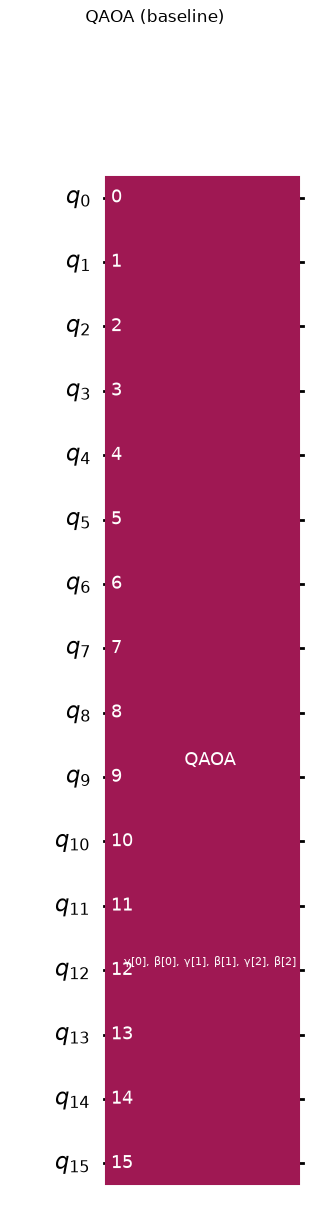

--- QAOA (warm-start): 16 qubits, 6 parameters ---


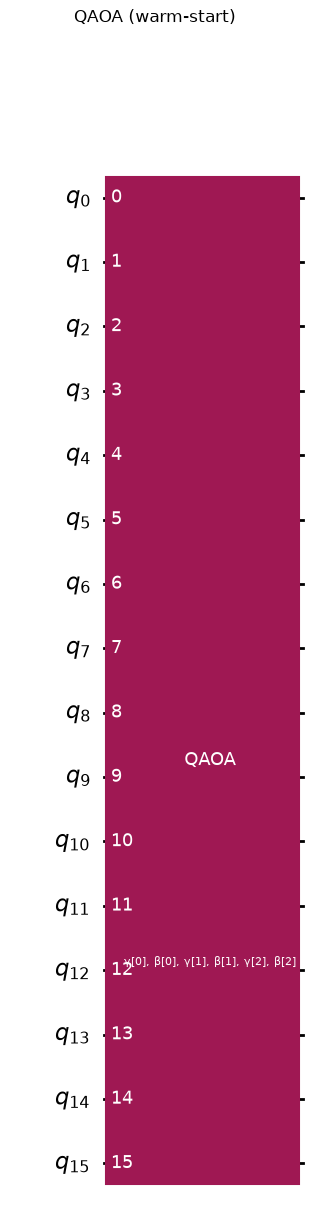

--- QAOA (XY-mixer): 16 qubits, 6 parameters ---


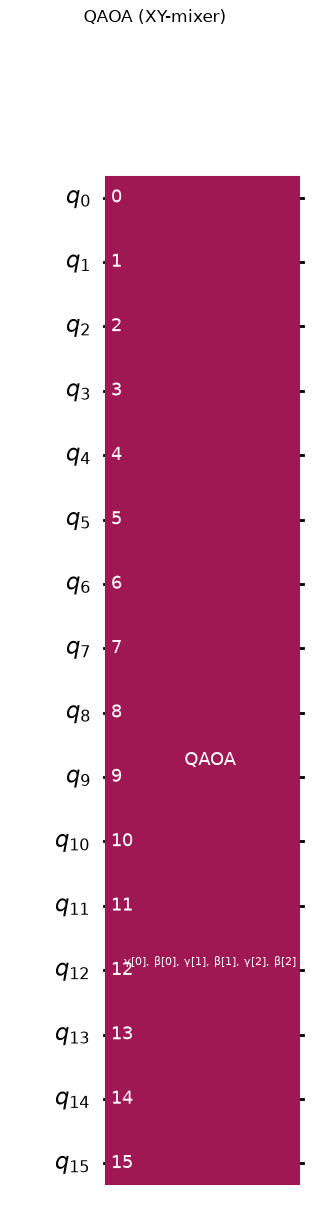

--- VQE (TwoLocal): 16 qubits, 128 parameters ---


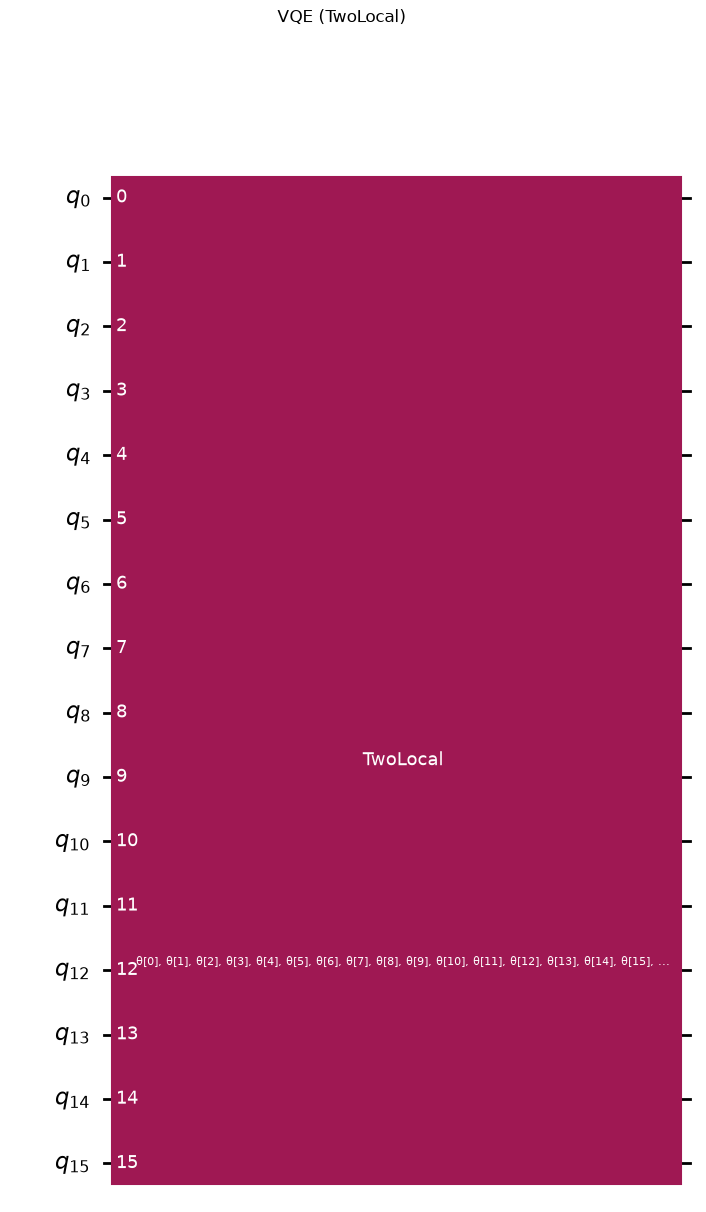

In [41]:
import sys, subprocess
try:
    import pylatexenc  # noqa: F401
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pylatexenc"])

from qiskit.circuit.library import TwoLocal
from IPython.display import display as ipy_display

# Compact, NON-decomposed versions of each ansatz built purely for visualization -- these
# show QAOA's alternating cost/mixer block structure (and VQE's rotation/entanglement layer
# structure) as a handful of labeled boxes, rather than the hundreds of elementary CX/RX
# gates the fully decomposed circuits (used for actual execution elsewhere) expand into.
viz_qaoa = QAOAAnsatz(cost_operator=ising_op, reps=QAOA_REPS)
viz_vqe = TwoLocal(ising_op.num_qubits, rotation_blocks=["ry", "rz"],
                    entanglement_blocks="cz", entanglement="linear", reps=VQE_REPS)
viz_warm = QAOAAnsatz(cost_operator=ising_op, reps=QAOA_REPS, initial_state=warm_init)
viz_xy = QAOAAnsatz(cost_operator=ising_op, reps=QAOA_REPS, initial_state=warm_init,
                     mixer_operator=xy_mixer)

circuits_to_draw = [
    ("QAOA (baseline)", viz_qaoa),
    ("QAOA (warm-start)", viz_warm),
    ("QAOA (XY-mixer)", viz_xy),
    ("VQE (TwoLocal)", viz_vqe),
]

for title, circ in circuits_to_draw:
    print(f"--- {title}: {circ.num_qubits} qubits, {circ.num_parameters} parameters ---")
    fig = circ.draw(output="mpl", fold=30)
    fig.suptitle(title, fontsize=12)
    ipy_display(fig)
    plt.close(fig)


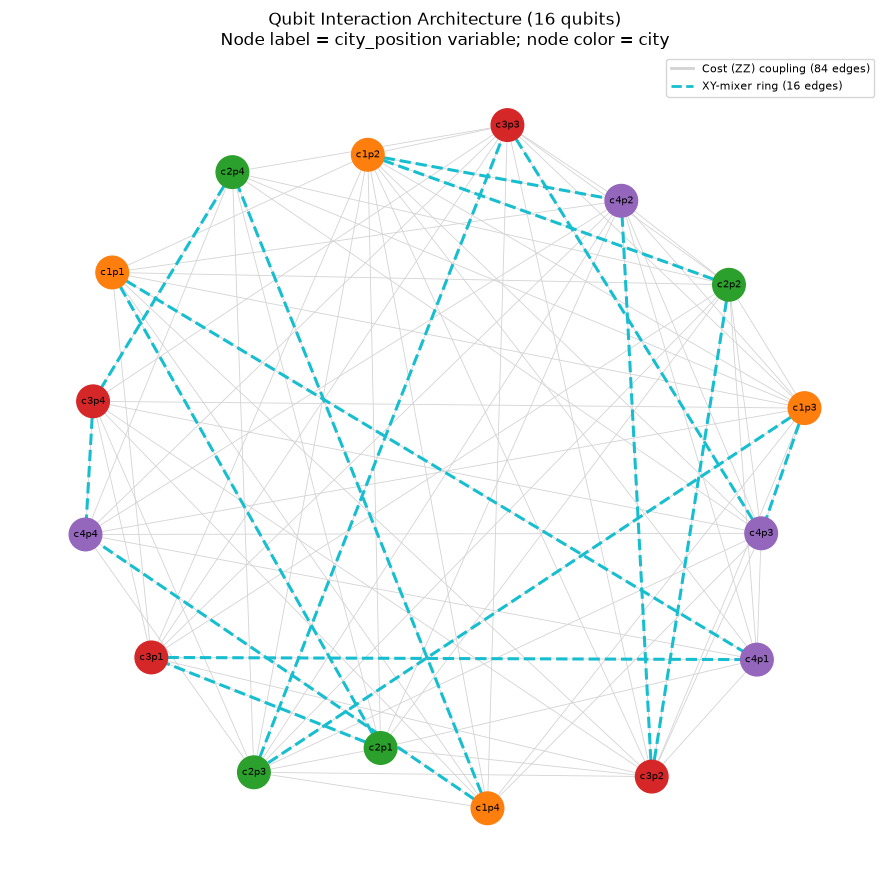

In [42]:
import networkx as nx
from matplotlib.lines import Line2D

var_names_viz = [v.name for v in qubo.variables]

G = nx.Graph()
for i, name in enumerate(var_names_viz):
    _, c_str, p_str = name.split("_")
    G.add_node(i, label=f"c{c_str}p{p_str}", city=int(c_str), position=int(p_str))

# Cost-Hamiltonian couplings: any Pauli term in `ising_op` touching exactly two qubits
cost_edges = set()
for pauli in ising_op.paulis:
    label = pauli.to_label()
    idxs = [k for k, ch in enumerate(label[::-1]) if ch != "I"]
    if len(idxs) == 2:
        cost_edges.add(tuple(sorted(idxs)))

# XY-mixer ring edges within each position block (from Section 20's position_blocks)
mixer_edges = set()
for block in position_blocks:
    m = len(block)
    if m == 2:
        mixer_edges.add(tuple(sorted(block)))
    else:
        for k in range(m):
            mixer_edges.add(tuple(sorted((block[k], block[(k + 1) % m]))))

fig, ax = plt.subplots(figsize=(9, 9))
pos = nx.spring_layout(G, seed=7, k=0.6)
node_colors = [plt.cm.tab10(G.nodes[n]["city"] % 10) for n in G.nodes]
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=550, ax=ax)
nx.draw_networkx_labels(G, pos, labels={n: G.nodes[n]["label"] for n in G.nodes},
                         font_size=7, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=list(cost_edges), edge_color="lightgray",
                        width=0.6, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=list(mixer_edges), edge_color="tab:cyan",
                        width=2.2, style="dashed", ax=ax)

legend_handles = [
    Line2D([0], [0], color="lightgray", lw=2, label=f"Cost (ZZ) coupling ({len(cost_edges)} edges)"),
    Line2D([0], [0], color="tab:cyan", lw=2, linestyle="--",
           label=f"XY-mixer ring ({len(mixer_edges)} edges)"),
]
ax.legend(handles=legend_handles, loc="upper right", fontsize=8)
ax.set_title(f"Qubit Interaction Architecture ({ising_op.num_qubits} qubits)\n"
             f"Node label = city_position variable; node color = city")
ax.axis("off")
plt.tight_layout()
plt.show()


# Reading the qubit interaction graph
Gray edges are fixed by the problem (Section 4's QUBO/Ising encoding) -- they don't change no matter which ansatz or mixer you pick. Cyan dashed edges are fixed by the mixer choice -- they only exist because Section 20 chose an XY-mixer that rings together each position's 4-qubit one-hot block. A denser gray graph generally means a harder cost landscape (more pairwise interactions for the optimizer to balance); the cyan rings show exactly which constraint the XY-mixer is structurally protecting -- and, by their absence, which one it isn't (there's no ring connecting qubits across different positions, which is why XY-mixer QAOA still can't guarantee the separate "each city used once" constraint on its own).

In [40]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output


def g(name):
    return globals().get(name)


def _missing_panel(section_name):
    out = widgets.Output()
    with out:
        print(f"Not available -- run the '{section_name}' section above first, "
              f"then rebuild the dashboard.")
    return out


def _overview_panel():
    out = widgets.Output()
    with out:
        main_tbl = g("results_with_vqe") if g("results_with_vqe") is not None else g("results")
        rows = []
        if main_tbl is not None:
            n_methods = len(main_tbl)
            best_nonexact = main_tbl[main_tbl["Method"] != "Brute Force (optimal)"].sort_values("Tour Length").iloc[0]
            rows.append(("Optimal tour length", f"{best_len:.4f}"))
            rows.append(("Instance", f"{N} cities ({source})"))
            rows.append(("Methods compared", str(n_methods)))
            rows.append(("Best non-exact method", f"{best_nonexact['Method']} "
                          f"({best_nonexact['Gap to Optimal (%)']:.2f}% gap)"))
        if g("best_qaoa_len") is not None:
            rows.append(("QAOA gap to optimal", f"{gap_pct(best_qaoa_len):.2f}%"))
        if g("best_vqe_len") is not None:
            rows.append(("VQE gap to optimal", f"{gap_pct(best_vqe_len):.2f}%"))
        if g("robust_df") is not None:
            rows.append(("Robustness seeds run", str(N_SEEDS)))
        if g("sweep_df") is not None:
            rows.append(("Hyperparameter configs swept", str(len(sweep_df))))
        if g("scale_df") is not None:
            rows.append(("Largest scalability instance", f"{int(scale_df['N'].max())} cities"))

        html = ['<div style="font-family:sans-serif">']
        html.append('<h3 style="margin-bottom:6px">TSP5 Benchmark -- Key Numbers</h3>')
        html.append('<table style="border-collapse:collapse">')
        for label, value in rows:
            html.append(
                '<tr><td style="padding:4px 14px 4px 0;color:#555">' + label + '</td>'
                '<td style="padding:4px 0;font-weight:600">' + value + '</td></tr>'
            )
        html.append('</table></div>')
        display(HTML("".join(html)))
    return out


def _comparison_panel():
    main_tbl = g("results_with_vqe") if g("results_with_vqe") is not None else g("results")
    if main_tbl is None:
        return _missing_panel("8. Compare All Methods")
    out = widgets.Output()
    with out:
        display(main_tbl)
        fig, ax = plt.subplots(figsize=(8, 4.5))
        colors_ = plt.cm.tab10(np.linspace(0, 1, len(main_tbl)))
        ax.bar(main_tbl["Method"], main_tbl["Tour Length"], color=colors_)
        ax.set_ylabel("Tour Length")
        ax.set_title("Method Comparison")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()
    return out


def _convergence_panel():
    series = [
        ("QAOA", g("qaoa_history"), "tab:purple"),
        ("VQE", g("vqe_history"), "tab:red"),
        ("GA", g("ga_history"), "tab:green"),
        ("SA", g("sa_history"), "tab:orange"),
    ]
    series = [(name, hist, color) for name, hist, color in series if hist is not None]
    if not series:
        return _missing_panel("5-7 / 14")
    out = widgets.Output()
    with out:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for name, hist, color in series:
            ax.plot(hist, label=name, color=color, linewidth=2)
        ax.axhline(best_len, color="black", linestyle="--", label="Optimal")
        ax.set_xlabel("Iteration / Generation")
        ax.set_ylabel("Best Objective Found So Far")
        ax.set_title("Convergence Across Methods")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
    return out


def _robustness_panel():
    if g("robust_df") is None or g("summary_df") is None:
        return _missing_panel("12. Multi-Seed Robustness Check")
    out = widgets.Output()
    with out:
        methods_ = [m for m in ("QAOA", "GA", "SA") if m in summary_df.index]
        fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
        means = [summary_df.loc[m, "Gap to Optimal (%)_mean"] for m in methods_]
        stds = [summary_df.loc[m, "Gap to Optimal (%)_std"] for m in methods_]
        colors_ = {"QAOA": "tab:purple", "GA": "tab:green", "SA": "tab:orange"}
        axes[0].bar(methods_, means, yerr=stds, capsize=6,
                    color=[colors_[m] for m in methods_], alpha=0.85)
        axes[0].set_ylabel("Gap to Optimal (%)")
        axes[0].set_title(f"Quality Across {N_SEEDS} Seeds (mean \u00b1 std)")
        axes[0].grid(alpha=0.3, axis="y")

        runtime_data = [robust_df.loc[robust_df["Method"] == m, "Runtime (s)"].values for m in methods_]
        bp = axes[1].boxplot(runtime_data, labels=methods_, patch_artist=True)
        for patch, m in zip(bp["boxes"], methods_):
            patch.set_facecolor(colors_[m])
            patch.set_alpha(0.6)
        axes[1].set_ylabel("Runtime (s)")
        axes[1].set_title("Runtime Spread")
        axes[1].grid(alpha=0.3, axis="y")
        plt.tight_layout()
        plt.show()
        display(summary_df)
    return out


def _sensitivity_panel():
    if g("sweep_df") is None or g("sweep_grid") is None:
        return _missing_panel("13. QAOA Hyperparameter Sensitivity Sweep")
    out = widgets.Output()
    with out:
        param_labels_ = {"reps": "reps", "shots": "shots", "maxiter": "maxiter", "penalty": "penalty"}
        fig, axes = plt.subplots(1, len(sweep_grid), figsize=(4 * len(sweep_grid), 4))
        if len(sweep_grid) == 1:
            axes = [axes]
        for ax, (param_name, values) in zip(axes, sweep_grid.items()):
            sub = sweep_df[sweep_df["Swept Param"] == param_name].sort_values("Value")
            ax.plot(sub["Value"], sub["Gap to Optimal (%)"], "o-", color="tab:purple")
            ax.set_xlabel(param_labels_.get(param_name, param_name))
            ax.set_ylabel("Gap to Optimal (%)")
            ax.set_title(param_name)
            ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
    return out


def _variants_panel():
    variant_data = []
    if g("best_qaoa_len") is not None:
        variant_data.append(("QAOA (baseline)", gap_pct(best_qaoa_len), 100 * valid_shots / FINAL_SHOTS, "tab:purple"))
    if g("warm_out") is not None:
        variant_data.append(("QAOA (warm-start)", gap_pct(warm_out["length"]), 100 * warm_out["valid_fraction"], "tab:blue"))
    if g("xy_out") is not None:
        variant_data.append(("QAOA (XY-mixer)", gap_pct(xy_out["length"]), 100 * xy_out["valid_fraction"], "tab:cyan"))
    if g("best_vqe_len") is not None:
        variant_data.append(("VQE", gap_pct(best_vqe_len), 100 * vqe_out["valid_fraction"], "tab:red"))
    if not variant_data:
        return _missing_panel("5, 14, 19, 20")
    out = widgets.Output()
    with out:
        names = [v[0] for v in variant_data]
        gaps = [v[1] for v in variant_data]
        valids = [v[2] for v in variant_data]
        colors_ = [v[3] for v in variant_data]
        fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
        axes[0].bar(names, gaps, color=colors_, alpha=0.85)
        axes[0].set_ylabel("Gap to Optimal (%)")
        axes[0].set_title("Quantum Ansatz/Mixer Variants: Solution Quality")
        axes[0].tick_params(axis="x", rotation=20)
        axes[0].grid(alpha=0.3, axis="y")
        axes[1].bar(names, valids, color=colors_, alpha=0.85)
        axes[1].set_ylabel("Valid Shot Fraction (%)")
        axes[1].set_title("Quantum Ansatz/Mixer Variants: Feasibility")
        axes[1].tick_params(axis="x", rotation=20)
        axes[1].grid(alpha=0.3, axis="y")
        plt.tight_layout()
        plt.show()
    return out


def _scalability_panel():
    if g("scale_df") is None:
        return _missing_panel("23. Scalability at Larger Instance Sizes")
    out = widgets.Output()
    with out:
        display(scale_df)
        fig, ax = plt.subplots(figsize=(7, 4.5))
        for method, color in [("NN", "tab:gray"), ("NN+2opt", "tab:blue"),
                               ("GA", "tab:green"), ("SA", "tab:orange")]:
            if f"{method} Length" in scale_df.columns:
                ax.plot(scale_df["N"], scale_df[f"{method} Length"], "o-", label=method, color=color)
        ax.set_xlabel("Number of Cities")
        ax.set_ylabel("Tour Length")
        ax.set_title("Classical Quality vs. Instance Size")
        ax.legend()
        ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
    return out


def build_dashboard():
    panels = [
        ("Overview", _overview_panel()),
        ("Comparison", _comparison_panel()),
        ("Convergence", _convergence_panel()),
        ("Robustness", _robustness_panel()),
        ("Sensitivity", _sensitivity_panel()),
        ("Quantum Variants", _variants_panel()),
        ("Scalability", _scalability_panel()),
    ]
    tab = widgets.Tab(children=[p for _, p in panels])
    tab.titles = [name for name, _ in panels]
    return tab


def on_refresh_clicked(_b):
    with dashboard_container:
        clear_output(wait=True)
        display(build_dashboard())


refresh_button = widgets.Button(description="Refresh Dashboard", icon="refresh",
                                 button_style="primary")
refresh_button.on_click(on_refresh_clicked)
dashboard_container = widgets.Output()

display(widgets.HTML("<h4>Run/rerun any section above, then click Refresh to update.</h4>"))
display(refresh_button)
display(dashboard_container)
with dashboard_container:
    display(build_dashboard())


HTML(value='<h4>Run/rerun any section above, then click Refresh to update.</h4>')

Button(button_style='primary', description='Refresh Dashboard', icon='refresh', style=ButtonStyle())

Output()